# MediRisk ML · Entregable 3
**Entrenamiento, evaluación y comparación de modelos para clasificar enfermedad cardiovascular con la base UCI Heart Disease completa (4 hospitales), incluido un LLM local (Qwen 3.5) con GPU**

Universidad ECCI · Ingeniería de Sistemas · Sistemas Inteligentes
Estudiantes: Juan Camilo Parra · Hector Julio Sierra · Docente: Andres Felipe Duque · Bogotá, 2026

**Qué hace este notebook, paso a paso**
1. Presenta las bases de datos públicas disponibles y justifica por qué ahora usamos la **UCI Heart Disease completa** (Cleveland + Hungría + Suiza + VA Long Beach, 920 registros) en lugar de solo Cleveland (303).
2. Explica cada variable y qué aporta, revisa los datos faltantes por hospital y prepara los datos sin fuga de información.
3. Explica la diferencia entre **pesos de clase** y **balanceo de clases**, y por qué elegimos pesos.
4. Entrena y ajusta **Regresión Logística, Árbol de Decisión, Random Forest y SVM**, los valida y evalúa una sola vez en prueba.
5. Interpreta los modelos (árbol dibujado, importancia de variables), mide su estabilidad y su desempeño por hospital.
6. Compara con un **modelo de lenguaje grande (Qwen 3.5 de 9 mil millones de parámetros)** ejecutado en local con Ollama y **GPU de 8 GB de VRAM**.
7. Guarda **todas las tablas y gráficas en un único archivo Excel** (`resultado/MediRisk_ML_Entregable3_resultados.xlsx`), cada una con su explicación: qué es, cómo leerla (ejes X e Y), el resultado y para qué sirve.

> **Aviso:** MediRisk ML es un ejercicio académico. Ningún resultado de este notebook constituye un diagnóstico médico.

## 0. Requisitos y equipo de pruebas

**Equipo en el que se ejecutaron las pruebas:** GNU/Linux **Arch Linux** con escritorio **KDE Plasma** sobre **Wayland**, procesador AMD Ryzen 3 2200G (4 núcleos), 16 GB de RAM DDR4 y GPU **NVIDIA GeForce RTX 3050 de 8 GB de VRAM**. La celda de la sección 1 lo detecta y lo imprime automáticamente.

**Bibliotecas de Python** (una sola vez):
```bash
pip install pandas numpy scikit-learn matplotlib seaborn openpyxl requests
```

**Ollama y Qwen** (una sola vez, en una terminal):
```bash
ollama pull qwen3.5:9b      # 6,6 GB; el Qwen más capaz que cabe completo en 8 GB de VRAM
ollama serve                # si el servicio no está corriendo ya
```

**Sobre el uso de la GPU**
- Los modelos de scikit-learn (Regresión Logística, Árbol, Random Forest, SVM) siempre corren en CPU: son livianos y scikit-learn no usa GPU.
- Qwen corre en la GPU: cada petición envía `"num_gpu": 99`, que pide cargar **todas las capas** del modelo en la VRAM. En la sección 10 se verifica con `/api/ps` cuántos GB quedaron en la GPU.
- Si se quiere repetir la prueba solo con CPU, basta con poner `USAR_GPU = False` (se envía `num_gpu = 0`).

Las predicciones de Qwen quedan guardadas dentro del Excel; si el notebook se vuelve a ejecutar con el mismo modelo, se reutilizan (borre el Excel para repetir el experimento).

## 1. Configuración y equipo de pruebas

In [1]:
import os, io, json, time, platform, subprocess, warnings, urllib.request
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import requests
from IPython.display import display, Markdown
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, ConfusionMatrixDisplay)

RS = 42
N_JOBS = 4                                   # núcleos del Ryzen 3 2200G
CARPETA_DATOS = "heart+disease"
OUT = "resultado"; os.makedirs(OUT, exist_ok=True)
EXCEL = f"{OUT}/MediRisk_ML_Entregable3_resultados.xlsx"
sns.set_theme(style="whitegrid")
COLORES = {"Línea base": "#8A8FA3", "Regresión Logística": "#2EC4B6", "Árbol de Decisión": "#3D8BFD",
           "Random Forest": "#E84855", "SVM": "#FF9B71", "Qwen zero-shot": "#6C63FF", "Qwen few-shot": "#3D348B", "Qwen razonamiento": "#B15EFF"}

# Todo lo que se muestra se registra aquí y al final se escribe en un único Excel
TABLAS, FIGURAS = {}, {}

def tabla(clave, df, titulo, que, leer, uso, resultado=""):
    TABLAS[clave] = dict(df=df.copy(), titulo=titulo, que=que, leer=leer, uso=uso, resultado=resultado)
    texto = f"**{titulo}**  \n*Qué es:* {que}  \n*Cómo leerla:* {leer}  \n"
    if resultado: texto += f"*Resultado:* {resultado}  \n"
    display(Markdown(texto + f"*Para qué sirve:* {uso}"))
    display(df)

def figura(clave, fig, titulo, eje_x, eje_y, que, uso, resultado=""):
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    FIGURAS[clave] = dict(png=buf.getvalue(), titulo=titulo, eje_x=eje_x, eje_y=eje_y, que=que, uso=uso, resultado=resultado)
    plt.show()
    display(Markdown(f"**Cómo leer la gráfica «{titulo}»**\n\n- **Eje X:** {eje_x}\n- **Eje Y:** {eje_y}\n"
                     f"- **Qué muestra:** {que}\n- **Resultado:** {resultado}\n- **Para qué sirve:** {uso}"))

def info_equipo():
    def cmd(c):
        try: return subprocess.run(c, capture_output=True, text=True, timeout=10).stdout.strip()
        except Exception: return ""
    so = platform.platform()
    if os.path.exists("/etc/os-release"):
        so = dict(l.strip().split("=", 1) for l in open("/etc/os-release") if "=" in l).get("PRETTY_NAME", so).strip('"')
    cpu = platform.processor()
    if os.path.exists("/proc/cpuinfo"):
        cpu = next((l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")), cpu)
    ram = ""
    if os.path.exists("/proc/meminfo"):
        ram = f"{int(open('/proc/meminfo').readline().split()[1]) / 1024**2:.1f} GB"
    gpu = cmd(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"]) or "no detectada"
    escritorio = os.environ.get("XDG_CURRENT_DESKTOP", "")
    version = cmd(["plasmashell", "--version"])
    return pd.DataFrame({"Valor": {
        "Sistema operativo": f"{so} (GNU/Linux)" if platform.system() == "Linux" else so,
        "Escritorio": f"{escritorio} {version.replace('plasmashell', 'Plasma').strip()}".strip() or "—",
        "Sesión gráfica": os.environ.get("XDG_SESSION_TYPE", "—"),
        "Procesador": f"{cpu} ({os.cpu_count()} hilos)", "Memoria RAM": ram, "GPU": gpu,
        "Python": platform.python_version()}})

tabla("T00_Equipo", info_equipo(), "Equipo de pruebas",
      "Hardware y sistema operativo en los que se ejecutó este notebook.",
      "Cada fila es un componente del equipo.",
      "Permite repetir el experimento en condiciones similares y entender los tiempos medidos (sobre todo los de Qwen, que dependen de la GPU).")

**Equipo de pruebas**  
*Qué es:* Hardware y sistema operativo en los que se ejecutó este notebook.  
*Cómo leerla:* Cada fila es un componente del equipo.  
*Para qué sirve:* Permite repetir el experimento en condiciones similares y entender los tiempos medidos (sobre todo los de Qwen, que dependen de la GPU).

,Valor
Sistema operativo,Arch Linux (GNU/Linux)
Escritorio,KDE Plasma 6.8.2
Sesión gráfica,wayland
Procesador,AMD Ryzen 3 2200G with Radeon Vega Graphics (4...
Memoria RAM,15.5 GB
GPU,"NVIDIA GeForce RTX 3050, 8192 MiB"
Python,3.11.18


## 2. ¿Qué bases de datos existen y por qué ampliamos a 920 registros?
Hasta el Entregable 2 trabajamos solo con el subconjunto **Cleveland** (303 pacientes), porque es el más completo y el más usado en la literatura, y queríamos primero entender bien los datos y montar un proceso limpio y reproducible. Con ese proceso ya validado, en este entregable incorporamos los otros tres hospitales del mismo repositorio para **triplicar la muestra sin cambiar las variables**.

In [2]:
bases = pd.DataFrame([
    ["UCI Heart Disease completa (Cleveland + Hungría + Suiza + VA Long Beach)", "920", "Las mismas 13 de nuestro proyecto",
     "Diagnóstico por angiografía. Mismo formato que ya usamos, pero con muchos faltantes en Suiza y VA"],
    ["Heart Failure Prediction (fedesoriano)", "918", "11", "Unión de las 5 bases clásicas de UCI, ya limpia"],
    ["Framingham Heart Study (versión Kaggle)", "~4.200", "15", "Riesgo de enfermedad coronaria a 10 años"],
    ["Cardiovascular Disease Dataset (Ulianova)", "70.000", "11", "Presión, colesterol, glucosa, IMC, hábitos. Balanceada (~50 %)"],
    ["Heart Disease Health Indicators, BRFSS 2015 (CDC)", "253.680", "21", "Encuesta de salud de EE. UU."],
    ["Personal Key Indicators of Heart Disease, BRFSS 2022 (CDC)", "~445.000 (~246.000 sin faltantes)", "~40", "Encuesta de salud de EE. UU."],
], columns=["Base", "Registros", "Variables", "Qué mide"])
tabla("T01_Bases_de_datos", bases, "Bases de datos públicas sobre enfermedad cardiovascular",
      "Comparación de las principales bases públicas que podríamos usar para este problema.",
      "Cada fila es una base: cuántos registros tiene, cuántas variables y qué mide su variable objetivo.",
      "Justificar la elección de datos: la UCI completa es la única que conserva nuestras 13 variables clínicas y el diagnóstico confirmado por angiografía. "
      "Las bases más grandes (70.000 a 445.000) miden otras variables (encuestas o hábitos), así que serían otro proyecto, no «más datos del mismo».",
      "Elegimos la UCI completa: triplica los datos (303 → 920) y mantiene las mismas variables y el mismo tipo de diagnóstico.")

**Bases de datos públicas sobre enfermedad cardiovascular**  
*Qué es:* Comparación de las principales bases públicas que podríamos usar para este problema.  
*Cómo leerla:* Cada fila es una base: cuántos registros tiene, cuántas variables y qué mide su variable objetivo.  
*Resultado:* Elegimos la UCI completa: triplica los datos (303 → 920) y mantiene las mismas variables y el mismo tipo de diagnóstico.  
*Para qué sirve:* Justificar la elección de datos: la UCI completa es la única que conserva nuestras 13 variables clínicas y el diagnóstico confirmado por angiografía. Las bases más grandes (70.000 a 445.000) miden otras variables (encuestas o hábitos), así que serían otro proyecto, no «más datos del mismo».

,Base,Registros,Variables,Qué mide
0,UCI Heart Disease completa (Cleveland + Hungrí...,920,Las mismas 13 de nuestro proyecto,Diagnóstico por angiografía. Mismo formato que...
1,Heart Failure Prediction (fedesoriano),918,11,"Unión de las 5 bases clásicas de UCI, ya limpia"
2,Framingham Heart Study (versión Kaggle),~4.200,15,Riesgo de enfermedad coronaria a 10 años
3,Cardiovascular Disease Dataset (Ulianova),70.000,11,"Presión, colesterol, glucosa, IMC, hábitos. Ba..."
4,"Heart Disease Health Indicators, BRFSS 2015 (CDC)",253.680,21,Encuesta de salud de EE. UU.
5,"Personal Key Indicators of Heart Disease, BRFS...",~445.000 (~246.000 sin faltantes),~40,Encuesta de salud de EE. UU.


## 3. Carga de los cuatro hospitales

In [3]:
COLS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
ARCHIVOS = {"Cleveland": "processed.cleveland.data", "Hungría": "processed.hungarian.data",
            "Suiza": "processed.switzerland.data", "VA Long Beach": "processed.va.data"}
URL_UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
os.makedirs(CARPETA_DATOS, exist_ok=True)
partes = []
for hospital, archivo in ARCHIVOS.items():
    ruta = os.path.join(CARPETA_DATOS, archivo)
    if not os.path.exists(ruta): urllib.request.urlretrieve(URL_UCI + archivo, ruta)
    p = pd.read_csv(ruta, names=COLS, na_values="?"); p["hospital"] = hospital; partes.append(p)
raw = pd.concat(partes, ignore_index=True)
print("Registros originales:", len(raw), "| duplicados exactos:", raw.duplicated().sum())
d = raw.drop_duplicates().reset_index(drop=True)
# Un 0 en colesterol o presión arterial es imposible: en estos archivos significa «no medido»
print("chol = 0:", (d.chol == 0).sum(), "| trestbps = 0:", (d.trestbps == 0).sum())
d.loc[d.chol == 0, "chol"] = np.nan
d.loc[d.trestbps == 0, "trestbps"] = np.nan
d["enfermedad"] = (d.num > 0).astype(int)           # 0 = ausencia, 1-4 = presencia
print("Registros únicos:", len(d))

por_h = d.groupby("hospital", sort=False).agg(Registros=("enfermedad", "size"), Con_enfermedad=("enfermedad", "sum"))
por_h["Sin_enfermedad"] = por_h.Registros - por_h.Con_enfermedad
por_h["% con enfermedad"] = (por_h.Con_enfermedad / por_h.Registros * 100).round(1)
por_h.loc["Total"] = [len(d), d.enfermedad.sum(), (d.enfermedad == 0).sum(), round(d.enfermedad.mean() * 100, 1)]
por_h = por_h.reset_index().rename(columns={"index": "hospital"})
tabla("T02_Pacientes_por_hospital", por_h, "Pacientes por hospital",
      "Cuántos pacientes aporta cada hospital y qué porcentaje tiene la enfermedad.",
      "Cada fila es un hospital; la última es el total. «% con enfermedad» es la prevalencia.",
      "Muestra que la prevalencia cambia mucho entre hospitales; por eso la división de datos se estratifica por clase y hospital, y se revisa el desempeño de cada hospital por separado.",
      f"Total {len(d)} pacientes; {d.enfermedad.mean()*100:.1f} % con enfermedad. Suiza tiene {por_h.set_index('hospital').loc['Suiza', '% con enfermedad']} % de enfermos y Hungría {por_h.set_index('hospital').loc['Hungría', '% con enfermedad']} %.")

Registros originales: 920 | duplicados exactos: 2
chol = 0: 172 | trestbps = 0: 1
Registros únicos: 918


**Pacientes por hospital**  
*Qué es:* Cuántos pacientes aporta cada hospital y qué porcentaje tiene la enfermedad.  
*Cómo leerla:* Cada fila es un hospital; la última es el total. «% con enfermedad» es la prevalencia.  
*Resultado:* Total 918 pacientes; 55.3 % con enfermedad. Suiza tiene 93.5 % de enfermos y Hungría 36.2 %.  
*Para qué sirve:* Muestra que la prevalencia cambia mucho entre hospitales; por eso la división de datos se estratifica por clase y hospital, y se revisa el desempeño de cada hospital por separado.

,hospital,Registros,Con_enfermedad,Sin_enfermedad,% con enfermedad
0,Cleveland,303,139,164,45.9
1,Hungría,293,106,187,36.2
2,Suiza,123,115,8,93.5
3,VA Long Beach,199,148,51,74.4
4,Total,918,508,410,55.3


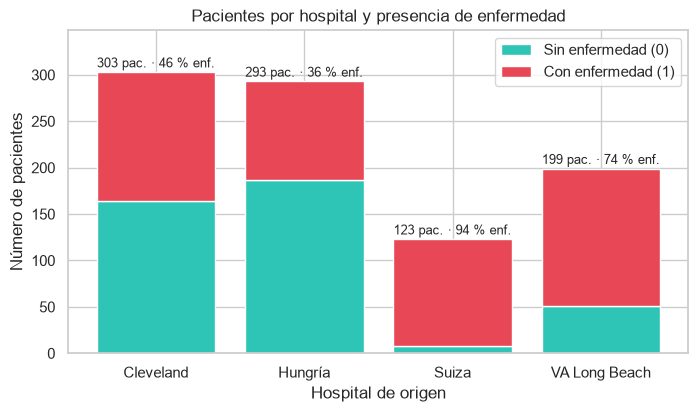

**Cómo leer la gráfica «Pacientes por hospital y presencia de enfermedad»**

- **Eje X:** Hospital de origen de los datos (Cleveland, Hungría, Suiza, VA Long Beach).
- **Eje Y:** Número de pacientes. Cada barra se divide en pacientes sin enfermedad (verde) y con enfermedad (rojo).
- **Qué muestra:** El tamaño de cada hospital y qué proporción de sus pacientes tiene la enfermedad.
- **Resultado:** Cleveland y Hungría aportan la mayoría de los datos; en Suiza y VA casi todos los pacientes están enfermos, mientras que en Hungría predominan los sanos.
- **Para qué sirve:** Saber de dónde vienen los datos y detectar diferencias entre poblaciones antes de entrenar.

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ph = por_h[por_h.hospital != "Total"].set_index("hospital")
ax.bar(ph.index, ph.Sin_enfermedad, color="#2EC4B6", label="Sin enfermedad (0)")
ax.bar(ph.index, ph.Con_enfermedad, bottom=ph.Sin_enfermedad, color="#E84855", label="Con enfermedad (1)")
for i, (h, r) in enumerate(ph.iterrows()):
    ax.text(i, r.Registros + 5, f"{int(r.Registros)} pac. · {r['% con enfermedad']:.0f} % enf.", ha="center", fontsize=9)
ax.set_xlabel("Hospital de origen"); ax.set_ylabel("Número de pacientes"); ax.set_ylim(0, ph.Registros.max() * 1.15)
ax.set_title("Pacientes por hospital y presencia de enfermedad"); ax.legend()
figura("G01_Pacientes_hospital", fig, "Pacientes por hospital y presencia de enfermedad",
       "Hospital de origen de los datos (Cleveland, Hungría, Suiza, VA Long Beach).",
       "Número de pacientes. Cada barra se divide en pacientes sin enfermedad (verde) y con enfermedad (rojo).",
       "El tamaño de cada hospital y qué proporción de sus pacientes tiene la enfermedad.",
       "Saber de dónde vienen los datos y detectar diferencias entre poblaciones antes de entrenar.",
       "Cleveland y Hungría aportan la mayoría de los datos; en Suiza y VA casi todos los pacientes están enfermos, mientras que en Hungría predominan los sanos.")

## 4. Las 13 variables: qué son y qué aportan

In [5]:
vars_info = pd.DataFrame([
    ["age", "Edad", "Numérica", "años", "El riesgo cardiovascular aumenta con la edad."],
    ["sex", "Sexo", "Binaria", "1 = hombre, 0 = mujer", "Los hombres presentan la enfermedad a edades más tempranas."],
    ["cp", "Tipo de dolor torácico", "Categórica", "angina típica, atípica, no anginoso, asintomático", "Paradójicamente, el dolor «asintomático» es el que más se asocia a enfermedad en estos datos."],
    ["trestbps", "Presión arterial en reposo", "Numérica", "mm Hg", "La hipertensión daña las arterias a largo plazo."],
    ["chol", "Colesterol sérico", "Numérica", "mg/dl", "Factor de riesgo clásico; aquí aporta poco por sí solo."],
    ["fbs", "Glucemia en ayunas > 120 mg/dl", "Binaria", "sí / no", "Indicador de diabetes, factor de riesgo."],
    ["restecg", "Electrocardiograma en reposo", "Categórica", "normal, anomalía ST-T, hipertrofia VI", "Detecta alteraciones eléctricas o de tamaño del corazón."],
    ["thalach", "Frecuencia cardíaca máxima", "Numérica", "latidos por minuto", "Un corazón enfermo alcanza frecuencias máximas más bajas en la prueba de esfuerzo."],
    ["exang", "Angina inducida por ejercicio", "Binaria", "sí / no", "Dolor al hacer esfuerzo: señal directa de flujo insuficiente."],
    ["oldpeak", "Depresión del segmento ST", "Numérica", "mm", "Cuánto «baja» el ECG con el esfuerzo; más depresión, más isquemia."],
    ["slope", "Pendiente del segmento ST", "Categórica", "ascendente, plana, descendente", "Plana o descendente sugiere isquemia."],
    ["ca", "Vasos coloreados por fluoroscopia", "Categórica", "0 a 3", "Más vasos con calcio visible, más riesgo; casi solo existe en Cleveland."],
    ["thal", "Prueba de talio", "Categórica", "normal, defecto fijo, defecto reversible", "El defecto reversible indica zonas del corazón con poco flujo al esforzarse."],
    ["enfermedad", "Variable objetivo", "Binaria", "0 = sin enfermedad, 1 = con enfermedad", "Estrechamiento > 50 % en al menos un vaso (angiografía)."],
], columns=["Variable", "Nombre", "Tipo", "Valores", "Qué aporta al proyecto"])
falt = d[COLS[:-1]].isna().mean().mul(100).round(1)
vars_info["% faltantes"] = vars_info.Variable.map(falt).fillna(0.0)
tabla("T03_Variables", vars_info, "Diccionario de variables",
      "Las 13 variables predictoras y la variable objetivo, con su significado clínico.",
      "Cada fila es una variable: nombre técnico, significado, tipo, valores posibles, qué aporta y qué porcentaje de datos falta.",
      "Entender qué información recibe el modelo y anticipar qué variables pueden ser problemáticas por los faltantes.",
      f"Las variables con más faltantes son ca ({falt['ca']:.0f} %), thal ({falt['thal']:.0f} %) y slope ({falt['slope']:.0f} %).")

**Diccionario de variables**  
*Qué es:* Las 13 variables predictoras y la variable objetivo, con su significado clínico.  
*Cómo leerla:* Cada fila es una variable: nombre técnico, significado, tipo, valores posibles, qué aporta y qué porcentaje de datos falta.  
*Resultado:* Las variables con más faltantes son ca (66 %), thal (53 %) y slope (33 %).  
*Para qué sirve:* Entender qué información recibe el modelo y anticipar qué variables pueden ser problemáticas por los faltantes.

,Variable,Nombre,Tipo,Valores,Qué aporta al proyecto,% faltantes
0,age,Edad,Numérica,años,El riesgo cardiovascular aumenta con la edad.,0.0
1,sex,Sexo,Binaria,"1 = hombre, 0 = mujer",Los hombres presentan la enfermedad a edades m...,0.0
2,cp,Tipo de dolor torácico,Categórica,"angina típica, atípica, no anginoso, asintomático","Paradójicamente, el dolor «asintomático» es el...",0.0
3,trestbps,Presión arterial en reposo,Numérica,mm Hg,La hipertensión daña las arterias a largo plazo.,6.5
4,chol,Colesterol sérico,Numérica,mg/dl,Factor de riesgo clásico; aquí aporta poco por...,21.9
5,fbs,Glucemia en ayunas > 120 mg/dl,Binaria,sí / no,"Indicador de diabetes, factor de riesgo.",9.8
6,restecg,Electrocardiograma en reposo,Categórica,"normal, anomalía ST-T, hipertrofia VI",Detecta alteraciones eléctricas o de tamaño de...,0.2
7,thalach,Frecuencia cardíaca máxima,Numérica,latidos por minuto,Un corazón enfermo alcanza frecuencias máximas...,6.0
8,exang,Angina inducida por ejercicio,Binaria,sí / no,Dolor al hacer esfuerzo: señal directa de fluj...,6.0
9,oldpeak,Depresión del segmento ST,Numérica,mm,Cuánto «baja» el ECG con el esfuerzo; más depr...,6.8


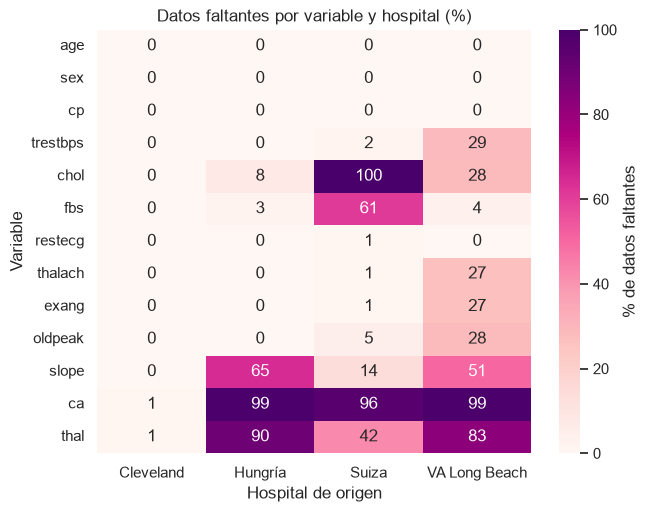

**Cómo leer la gráfica «Datos faltantes por variable y hospital»**

- **Eje X:** Hospital de origen de los datos.
- **Eje Y:** Variable clínica. El color y el número de cada casilla indican qué porcentaje de esa variable falta en ese hospital (0 = completa, 100 = no se registró nunca).
- **Qué muestra:** Dónde faltan datos. Cleveland está casi completo; en los otros tres hospitales faltan ca y thal casi siempre, y en Suiza no se midió el colesterol.
- **Resultado:** ca falta en 99 % de Hungría, 96 % de Suiza y 99 % de VA; chol falta en el 100 % de Suiza.
- **Para qué sirve:** Decidir cómo tratar los faltantes y advertir que una variable faltante puede delatar el hospital de origen.

In [6]:
falt_h = d.groupby("hospital", sort=False)[COLS[:-1]].apply(lambda g: g.isna().mean() * 100).T
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(falt_h, annot=True, fmt=".0f", cmap="RdPu", vmin=0, vmax=100, cbar_kws={"label": "% de datos faltantes"}, ax=ax)
ax.set_xlabel("Hospital de origen"); ax.set_ylabel("Variable"); ax.set_title("Datos faltantes por variable y hospital (%)")
figura("G02_Faltantes", fig, "Datos faltantes por variable y hospital",
       "Hospital de origen de los datos.",
       "Variable clínica. El color y el número de cada casilla indican qué porcentaje de esa variable falta en ese hospital (0 = completa, 100 = no se registró nunca).",
       "Dónde faltan datos. Cleveland está casi completo; en los otros tres hospitales faltan ca y thal casi siempre, y en Suiza no se midió el colesterol.",
       "Decidir cómo tratar los faltantes y advertir que una variable faltante puede delatar el hospital de origen.",
       f"ca falta en {falt_h.loc['ca', 'Hungría']:.0f} % de Hungría, {falt_h.loc['ca', 'Suiza']:.0f} % de Suiza y {falt_h.loc['ca', 'VA Long Beach']:.0f} % de VA; chol falta en el {falt_h.loc['chol', 'Suiza']:.0f} % de Suiza.")

## 5. Preparación de los datos (sin fuga de información)
- **Numéricas** (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`): los faltantes se completan con la **mediana** y se añade una columna indicadora «¿faltaba?»; después se **estandarizan** (media 0, desviación 1).
- **Categóricas** (`cp`, `restecg`, `slope`, `ca`, `thal`, `fbs`, `exang`): los faltantes se convierten en la categoría **«desconocido»** y se aplica **one-hot** (una columna 0/1 por categoría).
- Todo esto va dentro de un `Pipeline`: en cada partición de la validación cruzada la mediana, la escala y las categorías se aprenden **solo con los datos de entrenamiento de esa partición**. Así se evita la **fuga de información** (que el modelo «vea» datos de evaluación sin querer).
- División **70 / 15 / 15** estratificada por **clase y hospital** (`random_state = 42`).

In [7]:
ETIQ = {"cp": {1: "angina típica", 2: "angina atípica", 3: "dolor no anginoso", 4: "asintomático"},
        "restecg": {0: "normal", 1: "anomalía ST-T", 2: "hipertrofia VI"},
        "slope": {1: "ascendente", 2: "plana", 3: "descendente"},
        "thal": {3: "normal", 6: "defecto fijo", 7: "defecto reversible"},
        "ca": {0: "0", 1: "1", 2: "2", 3: "3"}, "fbs": {0: "no", 1: "sí"}, "exang": {0: "no", 1: "sí"}}
NUM, CAT, BIN = ["age", "trestbps", "chol", "thalach", "oldpeak"], list(ETIQ), ["sex"]
X = d[NUM + BIN].copy()
for c, m in ETIQ.items(): X[c] = d[c].map(m).fillna("desconocido")
y, hosp = d.enfermedad, d.hospital

def preprocesador(cat=CAT):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("esc", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ("bin", "passthrough", BIN)], verbose_feature_names_out=False)

estr = y.astype(str) + "_" + hosp
i_tmp, i_te = train_test_split(np.arange(len(d)), test_size=0.15, stratify=estr, random_state=RS)
i_tr, i_va = train_test_split(i_tmp, test_size=0.15 / 0.85, stratify=estr.iloc[i_tmp], random_state=RS)
X_tr, X_va, X_te = X.iloc[i_tr], X.iloc[i_va], X.iloc[i_te]
y_tr, y_va, y_te = y.iloc[i_tr], y.iloc[i_va], y.iloc[i_te]
h_te = hosp.iloc[i_te]

div = pd.DataFrame({n: hosp.iloc[i].value_counts() for n, i in (("Entrenamiento", i_tr), ("Validación", i_va), ("Prueba", i_te))}).loc[list(ARCHIVOS)]
div.loc["Total"] = div.sum()
div = div.astype(object)
div.loc["% con enfermedad"] = [round(y.iloc[i].mean() * 100, 1) for i in (i_tr, i_va, i_te)]
div = div.rename_axis("Hospital").reset_index()
tabla("T04_Division", div, "División de los datos en entrenamiento, validación y prueba",
      "Cuántos pacientes de cada hospital quedaron en cada conjunto.",
      "Columnas: los tres conjuntos. Filas: hospitales, total y porcentaje de enfermos en cada conjunto.",
      "Comprobar que los tres conjuntos son parecidos (mismos hospitales y misma proporción de enfermos), para que la evaluación sea justa.",
      f"Entrenamiento {len(i_tr)}, validación {len(i_va)} y prueba {len(i_te)} pacientes, todos con ≈ {y.mean()*100:.0f} % de enfermos.")
print("Columnas de entrada tras el preprocesamiento:", preprocesador().fit(X_tr).get_feature_names_out().size)

**División de los datos en entrenamiento, validación y prueba**  
*Qué es:* Cuántos pacientes de cada hospital quedaron en cada conjunto.  
*Cómo leerla:* Columnas: los tres conjuntos. Filas: hospitales, total y porcentaje de enfermos en cada conjunto.  
*Resultado:* Entrenamiento 642, validación 138 y prueba 138 pacientes, todos con ≈ 55 % de enfermos.  
*Para qué sirve:* Comprobar que los tres conjuntos son parecidos (mismos hospitales y misma proporción de enfermos), para que la evaluación sea justa.

,Hospital,Entrenamiento,Validación,Prueba
0,Cleveland,211,46,46
1,Hungría,205,44,44
2,Suiza,87,18,18
3,VA Long Beach,139,30,30
4,Total,642,138,138
5,% con enfermedad,55.5,55.1,55.1


Columnas de entrada tras el preprocesamiento: 37


## 6. Desbalance de clases: ¿pesos o balanceo?
Cuando una clase tiene muchos más ejemplos que la otra, el modelo tiende a favorecer a la mayoritaria. Hay dos soluciones:
- **Balanceo (remuestreo):** se cambian los datos. *Sobremuestreo* (duplicar o inventar con SMOTE pacientes de la clase minoritaria) o *submuestreo* (descartar pacientes de la mayoritaria).
- **Pesos de clase:** no se tocan los datos; se le dice al algoritmo que **equivocarse con la clase minoritaria cuesta más**. En scikit-learn es `class_weight="balanced"`: peso = total / (2 × pacientes de esa clase).

**Elegimos pesos** porque no inventa ni descarta pacientes, se aplica igual a los cuatro modelos con un solo parámetro, no hay riesgo de que pacientes sintéticos se filtren a validación o prueba y en datos pequeños funciona igual o mejor.

**Ojo:** «balanced» iguala la importancia de las dos clases. En la base de 4 hospitales la clase mayoritaria es «con enfermedad» (≈ 55 %), así que aquí los pesos favorecen un poco a los **sanos**. La tabla T08 mide ese efecto.

In [8]:
comp_met = pd.DataFrame([
    ["Pesos de clase (elegido)", "Da más peso a los errores en la clase minoritaria", "No altera los datos; un solo parámetro; sin riesgo de fuga", "Los pesos deben calcularse solo con entrenamiento"],
    ["Sobremuestreo (SMOTE)", "Crea pacientes sintéticos de la clase minoritaria", "Útil con desbalance extremo", "Pacientes inventados; si se aplica antes de dividir, contamina la prueba"],
    ["Submuestreo", "Elimina pacientes de la clase mayoritaria", "Rápido con bases enormes", "Pierde información real; grave con pocos datos"],
], columns=["Método", "Qué hace", "Ventajas", "Riesgos"])
tabla("T05_Pesos_vs_balanceo", comp_met, "Pesos de clase frente a balanceo",
      "Comparación de las tres formas de manejar el desbalance de clases.",
      "Cada fila es un método: qué hace, sus ventajas y sus riesgos.",
      "Justificar por qué usamos pesos de clase en todos los modelos.")

clases = np.array([0, 1])
w = compute_class_weight("balanced", classes=clases, y=y_tr)
pesos = pd.DataFrame({"Clase": ["Sin enfermedad (0)", "Con enfermedad (1)"], "Pacientes (entrenamiento)": [(y_tr == 0).sum(), (y_tr == 1).sum()],
                      "Proporción %": [round((y_tr == 0).mean() * 100, 1), round((y_tr == 1).mean() * 100, 1)], "Peso asignado": w.round(3)})
tabla("T06_Pesos_de_clase", pesos, "Pesos de clase calculados",
      "El peso que recibe cada clase con class_weight='balanced'.",
      "Una clase con menos pacientes recibe un peso mayor que 1; la mayoritaria, menor que 1.",
      "Ver cuánto corrige el modelo el desbalance. Aquí el desbalance global es leve, pero entre hospitales es fuerte (Suiza ≈ 93 % enfermos, Hungría ≈ 36 %).",
      f"Peso clase 0 = {w[0]:.2f}, clase 1 = {w[1]:.2f}.")

**Pesos de clase frente a balanceo**  
*Qué es:* Comparación de las tres formas de manejar el desbalance de clases.  
*Cómo leerla:* Cada fila es un método: qué hace, sus ventajas y sus riesgos.  
*Para qué sirve:* Justificar por qué usamos pesos de clase en todos los modelos.

,Método,Qué hace,Ventajas,Riesgos
0,Pesos de clase (elegido),Da más peso a los errores en la clase minoritaria,No altera los datos; un solo parámetro; sin ri...,Los pesos deben calcularse solo con entrenamiento
1,Sobremuestreo (SMOTE),Crea pacientes sintéticos de la clase minoritaria,Útil con desbalance extremo,Pacientes inventados; si se aplica antes de di...
2,Submuestreo,Elimina pacientes de la clase mayoritaria,Rápido con bases enormes,Pierde información real; grave con pocos datos


**Pesos de clase calculados**  
*Qué es:* El peso que recibe cada clase con class_weight='balanced'.  
*Cómo leerla:* Una clase con menos pacientes recibe un peso mayor que 1; la mayoritaria, menor que 1.  
*Resultado:* Peso clase 0 = 1.12, clase 1 = 0.90.  
*Para qué sirve:* Ver cuánto corrige el modelo el desbalance. Aquí el desbalance global es leve, pero entre hospitales es fuerte (Suiza ≈ 93 % enfermos, Hungría ≈ 36 %).

,Clase,Pacientes (entrenamiento),Proporción %,Peso asignado
0,Sin enfermedad (0),286,44.5,1.122
1,Con enfermedad (1),356,55.5,0.902


## 7. Modelos y ajuste de hiperparámetros
- **Línea base:** siempre predice la clase más frecuente. Es el piso que cualquier modelo útil debe superar.
- **Regresión Logística:** combina las variables linealmente y entrega una probabilidad.
- **Árbol de Decisión:** hace preguntas sí/no sobre las variables, como un diagrama de flujo.
- **Random Forest:** cientos de árboles distintos que votan; más estable que un árbol solo.
- **SVM:** busca la frontera que separa las clases con el mayor margen.

Los **hiperparámetros** (por ejemplo la profundidad del árbol) no se aprenden de los datos: se eligen probando combinaciones con **validación cruzada de 5 particiones** sobre entrenamiento y la métrica **ROC-AUC**. Todos los modelos usan `class_weight="balanced"`.

In [9]:
def metricas(y_true, y_pred, y_score):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_score) if len(np.unique(y_score)) > 1 else 0.5}

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
CW = "balanced"
candidatos = {
    "Regresión Logística": (LogisticRegression(max_iter=5000, class_weight=CW, random_state=RS), {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "Árbol de Decisión": (DecisionTreeClassifier(class_weight=CW, random_state=RS),
                          {"clf__max_depth": [2, 3, 4, 5, 6, 8], "clf__min_samples_leaf": [1, 5, 10, 20], "clf__criterion": ["gini", "entropy"]}),
    "Random Forest": (RandomForestClassifier(class_weight=CW, random_state=RS, n_jobs=1),
                      {"clf__n_estimators": [300], "clf__max_depth": [4, 6, None], "clf__min_samples_leaf": [1, 3, 5], "clf__max_features": ["sqrt", 0.5]}),
    "SVM": (SVC(probability=True, class_weight=CW, random_state=RS),
            {"clf__kernel": ["linear", "rbf"], "clf__C": [0.03, 0.1, 0.3, 1, 3, 10], "clf__gamma": ["scale", 0.01, 0.03, 0.1]}),
}
ML = list(candidatos)
modelos, filas = {}, []
for nombre, (est, grid) in candidatos.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(Pipeline([("prep", preprocesador()), ("clf", est)]), grid, cv=cv5, n_jobs=N_JOBS, refit="roc_auc",
                      scoring={"roc_auc": "roc_auc", "f1": "f1", "recall": "recall"})
    gs.fit(X_tr, y_tr); modelos[nombre] = gs.best_estimator_
    i, r = gs.best_index_, gs.cv_results_
    hp = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    if nombre == "SVM" and hp.get("kernel") == "linear": hp.pop("gamma", None)
    filas.append({"Modelo": nombre, "Mejores hiperparámetros": ", ".join(f"{k} = {v}" for k, v in hp.items()),
                  "CV ROC-AUC": round(r["mean_test_roc_auc"][i], 3), "± ROC-AUC": round(r["std_test_roc_auc"][i], 3),
                  "CV F1": round(r["mean_test_f1"][i], 3), "CV Recall": round(r["mean_test_recall"][i], 3),
                  "Combinaciones probadas": len(r["params"]), "Tiempo (s)": round(time.perf_counter() - t0, 1)})
t_hp = pd.DataFrame(filas)
mejor_cv = t_hp.sort_values("CV ROC-AUC", ascending=False).iloc[0]
tabla("T07_Hiperparametros", t_hp, "Ajuste de hiperparámetros con validación cruzada",
      "La mejor configuración encontrada para cada algoritmo y su desempeño promedio en 5 particiones de entrenamiento.",
      "«CV ROC-AUC» es el promedio en las 5 particiones (1 = perfecto, 0,5 = azar) y «±» su variación; F1 y Recall van de 0 a 1.",
      "Elegir la configuración de cada modelo sin tocar validación ni prueba, y tener una primera idea de cuál discrimina mejor.",
      f"El mayor ROC-AUC en validación cruzada fue de {mejor_cv.Modelo} ({mejor_cv['CV ROC-AUC']:.3f}).")

**Ajuste de hiperparámetros con validación cruzada**  
*Qué es:* La mejor configuración encontrada para cada algoritmo y su desempeño promedio en 5 particiones de entrenamiento.  
*Cómo leerla:* «CV ROC-AUC» es el promedio en las 5 particiones (1 = perfecto, 0,5 = azar) y «±» su variación; F1 y Recall van de 0 a 1.  
*Resultado:* El mayor ROC-AUC en validación cruzada fue de Regresión Logística (0.905).  
*Para qué sirve:* Elegir la configuración de cada modelo sin tocar validación ni prueba, y tener una primera idea de cuál discrimina mejor.

,Modelo,Mejores hiperparámetros,CV ROC-AUC,± ROC-AUC,CV F1,CV Recall,Combinaciones probadas,Tiempo (s)
0,Regresión Logística,C = 10,0.905,0.016,0.841,0.823,7,2.4
1,Árbol de Decisión,"criterion = entropy, max_depth = 4, min_sample...",0.835,0.014,0.810,0.815,48,3.5
2,Random Forest,"max_depth = 6, max_features = sqrt, min_sample...",0.892,0.020,0.828,0.826,18,16.9
3,SVM,"C = 0.03, kernel = linear",0.898,0.018,0.841,0.832,48,6.3


In [10]:
filas = []
for nombre in ML:
    fila = {"Modelo": nombre}
    for etiqueta, cw in (("sin pesos", None), ("con pesos", "balanced")):
        m = clone(modelos[nombre]).set_params(clf__class_weight=cw)
        r = cross_validate(m, X_tr, y_tr, cv=cv5, n_jobs=N_JOBS, scoring=["recall", "f1", "roc_auc"])
        for k in ("recall", "f1"): fila[f"{k.upper() if k == 'f1' else 'Recall'} {etiqueta}"] = round(r["test_" + k].mean(), 3)
    filas.append(fila)
t_pes = pd.DataFrame(filas)
tabla("T08_Efecto_pesos", t_pes, "Efecto de los pesos de clase",
      "Recall y F1 en validación cruzada de cada modelo, entrenado sin pesos y con pesos de clase.",
      "Comparar cada par de columnas: si «con pesos» es mayor o igual, los pesos ayudan o no perjudican.",
      "Medir con datos qué hacen realmente los pesos en nuestro problema.",
      f"En estos datos la clase mayoritaria es «con enfermedad» ({y_tr.mean()*100:.0f} %), así que los pesos dan un poco más de importancia a los sanos: "
      f"el Recall promedio pasa de {t_pes['Recall sin pesos'].mean():.3f} a {t_pes['Recall con pesos'].mean():.3f} y el F1 de {t_pes['F1 sin pesos'].mean():.3f} a {t_pes['F1 con pesos'].mean():.3f}. "
      "El efecto es pequeño; si se quisiera priorizar a los enfermos, habría que darles un peso mayor a propósito o bajar el umbral de decisión.")

**Efecto de los pesos de clase**  
*Qué es:* Recall y F1 en validación cruzada de cada modelo, entrenado sin pesos y con pesos de clase.  
*Cómo leerla:* Comparar cada par de columnas: si «con pesos» es mayor o igual, los pesos ayudan o no perjudican.  
*Resultado:* En estos datos la clase mayoritaria es «con enfermedad» (55 %), así que los pesos dan un poco más de importancia a los sanos: el Recall promedio pasa de 0.852 a 0.824 y el F1 de 0.839 a 0.830. El efecto es pequeño; si se quisiera priorizar a los enfermos, habría que darles un peso mayor a propósito o bajar el umbral de decisión.  
*Para qué sirve:* Medir con datos qué hacen realmente los pesos en nuestro problema.

,Modelo,Recall sin pesos,F1 sin pesos,Recall con pesos,F1 con pesos
0,Regresión Logística,0.857,0.850,0.823,0.841
1,Árbol de Decisión,0.817,0.819,0.815,0.810
2,Random Forest,0.871,0.838,0.826,0.828
3,SVM,0.862,0.847,0.832,0.841


## 8. Validación, selección y evaluación final en prueba

In [11]:
base = Pipeline([("prep", preprocesador()), ("clf", DummyClassifier(strategy="most_frequent"))]).fit(X_tr, y_tr)
fv = {"Línea base": metricas(y_va, base.predict(X_va), base.predict_proba(X_va)[:, 1])}
for n, m in modelos.items(): fv[n] = metricas(y_va, m.predict(X_va), m.predict_proba(X_va)[:, 1])
t_va = pd.DataFrame(fv).T.round(3)
seleccionado = t_va.drop(index="Línea base").sort_values(["F1", "Recall", "ROC-AUC"], ascending=False).index[0]
tabla("T09_Metricas_validacion", t_va.reset_index().rename(columns={"index": "Modelo"}), "Métricas en el conjunto de validación",
      f"Desempeño de cada modelo en {len(y_va)} pacientes que no se usaron para entrenar.",
      "Cada fila es un modelo; las métricas van de 0 a 1 (más alto es mejor).",
      "Seleccionar el modelo: priorizamos F1 y, en empate, Recall, porque omitir a un enfermo es el error más grave.",
      f"Modelo seleccionado con validación: {seleccionado}.")

X_trva, y_trva = pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va])
finales, scores, tiempos = {}, {}, {}
ft = {"Línea base": metricas(y_te, base.predict(X_te), base.predict_proba(X_te)[:, 1])}
for n, m in modelos.items():
    f = clone(m).fit(X_trva, y_trva); finales[n] = f
    t0 = time.perf_counter(); p = f.predict_proba(X_te)[:, 1]; tiempos[n] = (time.perf_counter() - t0) / len(X_te)
    scores[n] = p; ft[n] = metricas(y_te, (p >= 0.5).astype(int), p)
t_te = pd.DataFrame(ft).T.round(3)
mej = t_te.drop(index="Línea base").F1.idxmax()
tabla("T10_Metricas_prueba", t_te.reset_index().rename(columns={"index": "Modelo"}), "Métricas en el conjunto de prueba",
      f"Evaluación final, una sola vez, en {len(y_te)} pacientes nunca vistos. Cada modelo se reentrenó con entrenamiento + validación.",
      "Accuracy = aciertos totales; Precision = de los que el modelo llama enfermos, cuántos lo son; Recall = de los enfermos reales, cuántos detecta; F1 = equilibrio entre ambos; ROC-AUC = capacidad de ordenar enfermos por encima de sanos.",
      "Es la estimación más honesta de cómo funcionaría cada modelo con pacientes nuevos.",
      f"Mejor F1 en prueba: {mej} ({t_te.loc[mej, 'F1']:.3f}); la línea base solo acierta el {t_te.loc['Línea base', 'Accuracy']*100:.1f} %.")

**Métricas en el conjunto de validación**  
*Qué es:* Desempeño de cada modelo en 138 pacientes que no se usaron para entrenar.  
*Cómo leerla:* Cada fila es un modelo; las métricas van de 0 a 1 (más alto es mejor).  
*Resultado:* Modelo seleccionado con validación: Random Forest.  
*Para qué sirve:* Seleccionar el modelo: priorizamos F1 y, en empate, Recall, porque omitir a un enfermo es el error más grave.

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Línea base,0.551,0.551,1.000,0.710,0.500
1,Regresión Logística,0.783,0.811,0.789,0.800,0.865
2,Árbol de Decisión,0.790,0.770,0.882,0.822,0.818
3,Random Forest,0.826,0.833,0.855,0.844,0.907
4,SVM,0.804,0.818,0.829,0.824,0.888


**Métricas en el conjunto de prueba**  
*Qué es:* Evaluación final, una sola vez, en 138 pacientes nunca vistos. Cada modelo se reentrenó con entrenamiento + validación.  
*Cómo leerla:* Accuracy = aciertos totales; Precision = de los que el modelo llama enfermos, cuántos lo son; Recall = de los enfermos reales, cuántos detecta; F1 = equilibrio entre ambos; ROC-AUC = capacidad de ordenar enfermos por encima de sanos.  
*Resultado:* Mejor F1 en prueba: SVM (0.877); la línea base solo acierta el 55.1 %.  
*Para qué sirve:* Es la estimación más honesta de cómo funcionaría cada modelo con pacientes nuevos.

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Línea base,0.551,0.551,1.000,0.710,0.500
1,Regresión Logística,0.819,0.849,0.816,0.832,0.913
2,Árbol de Decisión,0.761,0.772,0.803,0.787,0.855
3,Random Forest,0.841,0.855,0.855,0.855,0.910
4,SVM,0.862,0.861,0.895,0.877,0.916


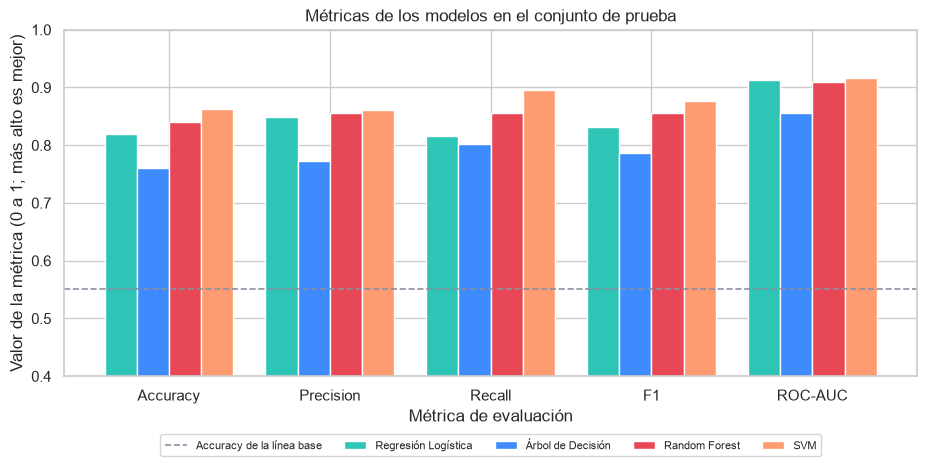

**Cómo leer la gráfica «Métricas de los modelos en el conjunto de prueba»**

- **Eje X:** Las cinco métricas de evaluación (Accuracy, Precision, Recall, F1 y ROC-AUC).
- **Eje Y:** Valor de cada métrica, de 0 a 1; más alto es mejor. La línea punteada es la exactitud de la línea base.
- **Qué muestra:** Cómo le fue a cada modelo en cada métrica, uno al lado del otro.
- **Resultado:** SVM tiene el F1 más alto (0.877); todos superan con amplitud a la línea base.
- **Para qué sirve:** Comparar los modelos de un vistazo y ver en qué métrica destaca cada uno.

In [12]:
mets = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, ax = plt.subplots(figsize=(11, 4.5))
t_te.loc[ML, mets].T.plot.bar(ax=ax, width=0.8, color=[COLORES[m] for m in ML], rot=0)
ax.axhline(t_te.loc["Línea base", "Accuracy"], ls="--", color="#8A8FA3", lw=1.2, label="Accuracy de la línea base")
ax.set_ylim(0.4, 1.0); ax.set_xlabel("Métrica de evaluación"); ax.set_ylabel("Valor de la métrica (0 a 1; más alto es mejor)")
ax.set_title("Métricas de los modelos en el conjunto de prueba"); ax.legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.15))
figura("G03_Metricas_prueba", fig, "Métricas de los modelos en el conjunto de prueba",
       "Las cinco métricas de evaluación (Accuracy, Precision, Recall, F1 y ROC-AUC).",
       "Valor de cada métrica, de 0 a 1; más alto es mejor. La línea punteada es la exactitud de la línea base.",
       "Cómo le fue a cada modelo en cada métrica, uno al lado del otro.",
       "Comparar los modelos de un vistazo y ver en qué métrica destaca cada uno.",
       f"{mej} tiene el F1 más alto ({t_te.loc[mej, 'F1']:.3f}); todos superan con amplitud a la línea base.")

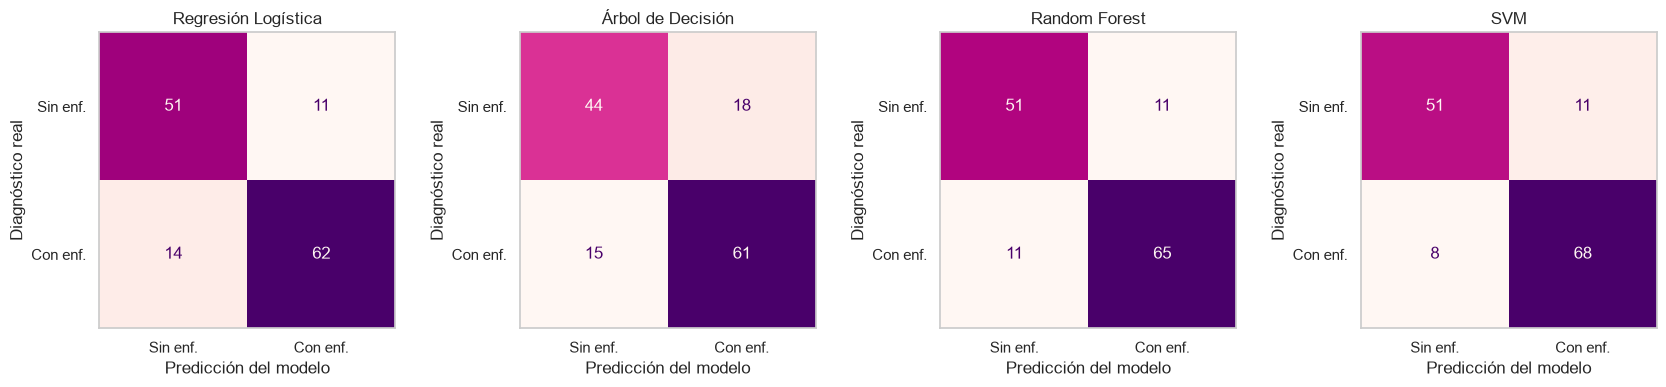

**Cómo leer la gráfica «Matrices de confusión en prueba»**

- **Eje X:** Lo que predijo el modelo: «Sin enf.» o «Con enf.».
- **Eje Y:** El diagnóstico real del paciente. Diagonal = aciertos; abajo a la izquierda = falsos negativos (enfermos no detectados); arriba a la derecha = falsos positivos (sanos alertados).
- **Qué muestra:** Cuántos pacientes acertó y en qué se equivocó cada modelo.
- **Resultado:** Falsos negativos: Regresión Logística 14, Árbol de Decisión 15, Random Forest 11, SVM 8 de 76 enfermos.
- **Para qué sirve:** Medir el error más grave en salud (falsos negativos) y decidir si conviene ajustar el umbral.

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
for a, n in zip(ax, ML):
    ConfusionMatrixDisplay(confusion_matrix(y_te, (scores[n] >= 0.5).astype(int)), display_labels=["Sin enf.", "Con enf."]).plot(ax=a, cmap="RdPu", colorbar=False)
    a.set_title(n); a.set_xlabel("Predicción del modelo"); a.set_ylabel("Diagnóstico real"); a.grid(False)
plt.tight_layout()
fn = {n: int(confusion_matrix(y_te, (scores[n] >= 0.5).astype(int))[1, 0]) for n in ML}
figura("G04_Matrices_confusion", fig, "Matrices de confusión en prueba",
       "Lo que predijo el modelo: «Sin enf.» o «Con enf.».",
       "El diagnóstico real del paciente. Diagonal = aciertos; abajo a la izquierda = falsos negativos (enfermos no detectados); arriba a la derecha = falsos positivos (sanos alertados).",
       "Cuántos pacientes acertó y en qué se equivocó cada modelo.",
       "Medir el error más grave en salud (falsos negativos) y decidir si conviene ajustar el umbral.",
       "Falsos negativos: " + ", ".join(f"{n} {v}" for n, v in fn.items()) + f" de {int(y_te.sum())} enfermos.")

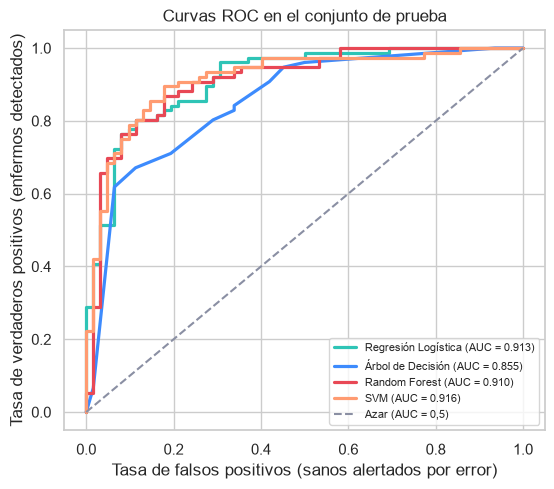

**Cómo leer la gráfica «Curvas ROC en el conjunto de prueba»**

- **Eje X:** Tasa de falsos positivos: proporción de pacientes sanos que el modelo marca como enfermos (0 a 1).
- **Eje Y:** Tasa de verdaderos positivos (Recall): proporción de enfermos que el modelo detecta (0 a 1).
- **Qué muestra:** Cada curva recorre todos los umbrales de decisión posibles. Cuanto más se pega a la esquina superior izquierda, mejor; el área bajo la curva (AUC) lo resume.
- **Resultado:** Mejor AUC: SVM (0.916).
- **Para qué sirve:** Elegir el umbral según la prioridad: por ejemplo, aceptar más falsas alarmas a cambio de no dejar enfermos sin detectar.

In [14]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
for n in ML:
    fpr, tpr, _ = roc_curve(y_te, scores[n])
    ax.plot(fpr, tpr, lw=2.3, color=COLORES[n], label=f"{n} (AUC = {roc_auc_score(y_te, scores[n]):.3f})")
ax.plot([0, 1], [0, 1], "--", color="#8A8FA3", label="Azar (AUC = 0,5)")
ax.set_xlabel("Tasa de falsos positivos (sanos alertados por error)"); ax.set_ylabel("Tasa de verdaderos positivos (enfermos detectados)")
ax.set_title("Curvas ROC en el conjunto de prueba"); ax.legend(loc="lower right", fontsize=8)
figura("G05_Curvas_ROC", fig, "Curvas ROC en el conjunto de prueba",
       "Tasa de falsos positivos: proporción de pacientes sanos que el modelo marca como enfermos (0 a 1).",
       "Tasa de verdaderos positivos (Recall): proporción de enfermos que el modelo detecta (0 a 1).",
       "Cada curva recorre todos los umbrales de decisión posibles. Cuanto más se pega a la esquina superior izquierda, mejor; el área bajo la curva (AUC) lo resume.",
       "Elegir el umbral según la prioridad: por ejemplo, aceptar más falsas alarmas a cambio de no dejar enfermos sin detectar.",
       "Mejor AUC: " + max(ML, key=lambda n: roc_auc_score(y_te, scores[n])) + f" ({max(roc_auc_score(y_te, scores[n]) for n in ML):.3f}).")

## 9. Interpretación
### 9.1 El Árbol de Decisión dibujado
Un árbol de decisión clasifica con preguntas sí/no. Se lee **de arriba hacia abajo**: en cada caja se pregunta por una variable; si la respuesta es «sí» se baja por la izquierda y si es «no» por la derecha, hasta llegar a una hoja que da la clase.

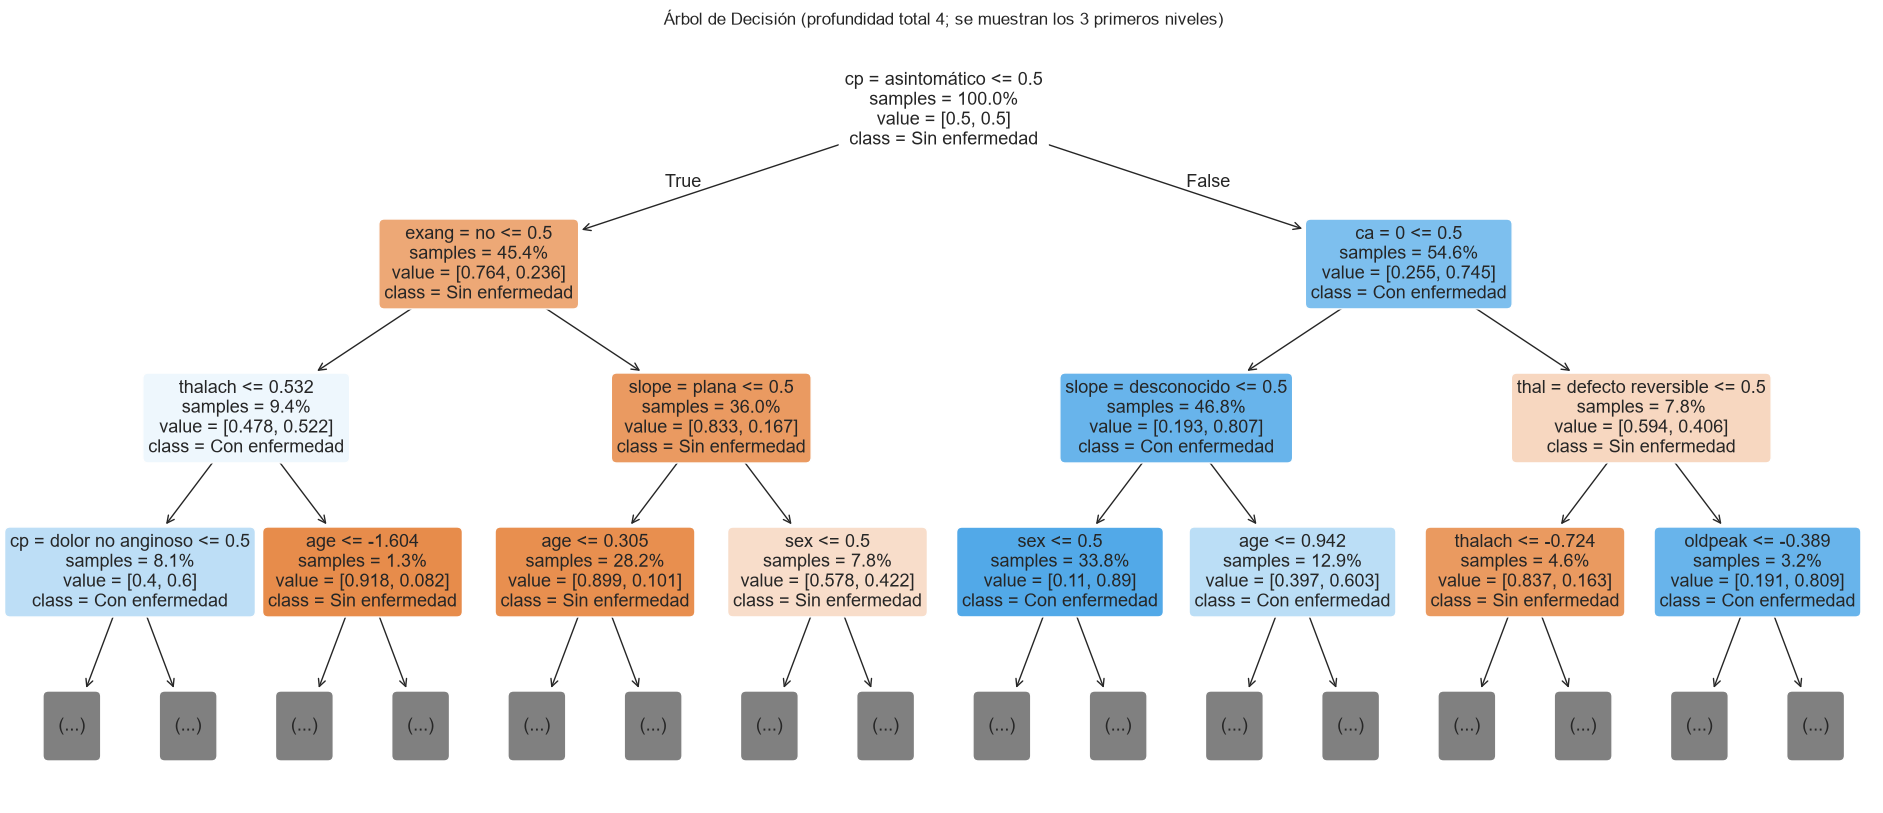

**Cómo leer la gráfica «Árbol de Decisión»**

- **Eje X:** No tiene eje X: el árbol se lee de arriba hacia abajo.
- **Eje Y:** No tiene eje Y: cada nivel hacia abajo es una pregunta más.
- **Qué muestra:** Cada caja muestra la pregunta (ej. «oldpeak <= 0,5»), el porcentaje de pacientes que llega ahí, la proporción [sin, con] enfermedad y la clase mayoritaria. Más rojo = más enfermos; más azul = más sanos. Las variables numéricas están estandarizadas (0 = valor promedio). Las variables de tipo «cp = asintomático <= 0,5» significan «¿NO es asintomático?».
- **Resultado:** La primera pregunta del árbol es sobre «cp = asintomático», la variable que mejor separa a enfermos de sanos.
- **Para qué sirve:** Explicar con reglas simples cómo decide un modelo y validar que esas reglas tengan sentido clínico.

|--- cp = asintomático <= 0.50
|   |--- exang = no <= 0.50
|   |   |--- thalach <= 0.53
|   |   |   |--- cp = dolor no anginoso <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- cp = dolor no anginoso >  0.50
|   |   |   |   |--- class: 1
|   |   |--- thalach >  0.53
|   |   |   |--- age <= -1.60
|   |   |   |   |--- class: 1
|   |   |   |--- age >  -1.60
|   |   |   |   |--- class: 0
|   |--- exang = no >  0.50
|   |   |--- slope = plana <= 0.50
|   |   |   |--- age <= 0.31
|   |   |   |   |--- class: 0
|   |   |   |--- age >  0.31
|   |   |   |   |--- class: 0
|   |   |--- slope = plana >  0.50
|   |   |   |--- sex <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- sex >  0.50
|   |   |   |   |--- class: 1
|--- cp = asintomático >  0.50
|   |--- ca = 0 <= 0.50
|   |   |--- slope = desconocido <= 0.50
|   |   |   |--- sex <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- sex >  0.50
|   |   |   |   |--- class: 1
|   |   |--- slope = desconocido >  0.50
|   |   |   |--- a

In [15]:
arbol = finales["Árbol de Decisión"]
nombres = arbol.named_steps["prep"].get_feature_names_out()
legible = lambda s: s.replace("missingindicator_", "falta_").replace("_", " = ", 1) if any(s.startswith(c + "_") for c in CAT) else s.replace("missingindicator_", "falta_")
nombres_l = [legible(s) for s in nombres]
prof = arbol.named_steps["clf"].get_depth()
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(arbol.named_steps["clf"], max_depth=3, feature_names=nombres_l, class_names=["Sin enfermedad", "Con enfermedad"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=13, ax=ax)
ax.set_title(f"Árbol de Decisión (profundidad total {prof}; se muestran los 3 primeros niveles)")
raiz = nombres_l[arbol.named_steps["clf"].tree_.feature[0]]
figura("G06_Arbol_decision", fig, "Árbol de Decisión",
       "No tiene eje X: el árbol se lee de arriba hacia abajo.",
       "No tiene eje Y: cada nivel hacia abajo es una pregunta más.",
       "Cada caja muestra la pregunta (ej. «oldpeak <= 0,5»), el porcentaje de pacientes que llega ahí, la proporción [sin, con] enfermedad y la clase mayoritaria. Más rojo = más enfermos; más azul = más sanos. "
       "Las variables numéricas están estandarizadas (0 = valor promedio). Las variables de tipo «cp = asintomático <= 0,5» significan «¿NO es asintomático?».",
       "Explicar con reglas simples cómo decide un modelo y validar que esas reglas tengan sentido clínico.",
       f"La primera pregunta del árbol es sobre «{raiz}», la variable que mejor separa a enfermos de sanos.")
reglas = pd.DataFrame({"Regla": export_text(arbol.named_steps["clf"], feature_names=nombres_l, max_depth=4).splitlines()})
TABLAS["T11_Reglas_arbol"] = dict(df=reglas, titulo="Reglas del Árbol de Decisión (texto)", que="El árbol escrito como reglas si/entonces.",
    leer="Cada sangría es un nivel más profundo; «class» es la predicción final de esa rama.", uso="Leer o copiar las reglas exactas del árbol.", resultado="")
print(export_text(arbol.named_steps["clf"], feature_names=nombres_l, max_depth=3))

### 9.2 Variables más importantes

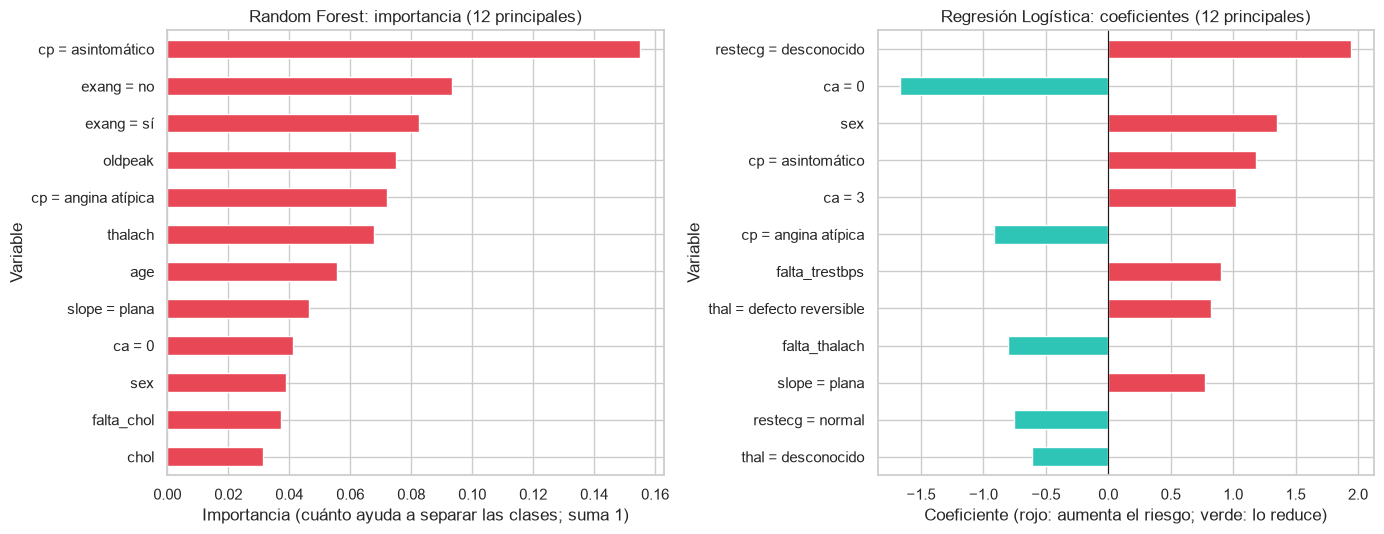

**Cómo leer la gráfica «Variables más importantes»**

- **Eje X:** Izquierda: importancia en Random Forest (0 a 1). Derecha: coeficiente de la Regresión Logística (positivo aumenta el riesgo, negativo lo reduce).
- **Eje Y:** Variable o categoría (por ejemplo «cp = asintomático»; «falta_chol» indica que el colesterol no se midió).
- **Qué muestra:** Qué información usan más los modelos para decidir.
- **Resultado:** Las más influyentes en Random Forest: cp = asintomático, exang = no, exang = sí, oldpeak, cp = angina atípica.
- **Para qué sirve:** Validar que el modelo se apoya en variables con sentido clínico y detectar señales sospechosas (por ejemplo, variables que delatan el hospital).

**Importancia de variables (valores)**  
*Qué es:* Los valores numéricos de la gráfica anterior.  
*Cómo leerla:* Importancia RF: mayor = más útil. Coeficiente RL: signo + aumenta el riesgo, signo − lo reduce.  
*Para qué sirve:* Consultar o citar los valores exactos.

,Variable RF,Importancia RF,Variable RL,Coeficiente RL
0,cp = asintomático,0.155,restecg = desconocido,1.947
1,exang = no,0.093,ca = 0,-1.667
2,exang = sí,0.083,sex,1.351
3,oldpeak,0.075,cp = asintomático,1.186
4,cp = angina atípica,0.072,ca = 3,1.023
5,thalach,0.068,cp = angina atípica,-0.911
6,age,0.056,falta_trestbps,0.901
7,slope = plana,0.047,thal = defecto reversible,0.824
8,ca = 0,0.041,falta_thalach,-0.803
9,sex,0.039,slope = plana,0.771


In [16]:
rf, rl = finales["Random Forest"], finales["Regresión Logística"]
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=[legible(s) for s in rf.named_steps["prep"].get_feature_names_out()]).sort_values(ascending=False)
coef = pd.Series(rl.named_steps["clf"].coef_[0], index=[legible(s) for s in rl.named_steps["prep"].get_feature_names_out()]).sort_values(key=abs, ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
imp.head(12)[::-1].plot.barh(ax=ax[0], color="#E84855")
ax[0].set_title("Random Forest: importancia (12 principales)"); ax[0].set_xlabel("Importancia (cuánto ayuda a separar las clases; suma 1)"); ax[0].set_ylabel("Variable")
c = coef.head(12)[::-1]
c.plot.barh(ax=ax[1], color=["#E84855" if v > 0 else "#2EC4B6" for v in c]); ax[1].axvline(0, color="k", lw=.8)
ax[1].set_title("Regresión Logística: coeficientes (12 principales)"); ax[1].set_xlabel("Coeficiente (rojo: aumenta el riesgo; verde: lo reduce)"); ax[1].set_ylabel("Variable")
plt.tight_layout()
figura("G07_Importancia_variables", fig, "Variables más importantes",
       "Izquierda: importancia en Random Forest (0 a 1). Derecha: coeficiente de la Regresión Logística (positivo aumenta el riesgo, negativo lo reduce).",
       "Variable o categoría (por ejemplo «cp = asintomático»; «falta_chol» indica que el colesterol no se midió).",
       "Qué información usan más los modelos para decidir.",
       "Validar que el modelo se apoya en variables con sentido clínico y detectar señales sospechosas (por ejemplo, variables que delatan el hospital).",
       "Las más influyentes en Random Forest: " + ", ".join(imp.head(5).index) + ".")
tabla("T12_Importancia", pd.DataFrame({"Variable RF": imp.head(15).index, "Importancia RF": imp.head(15).round(3).values,
      "Variable RL": coef.head(15).index, "Coeficiente RL": coef.head(15).round(3).values}),
      "Importancia de variables (valores)", "Los valores numéricos de la gráfica anterior.",
      "Importancia RF: mayor = más útil. Coeficiente RL: signo + aumenta el riesgo, signo − lo reduce.",
      "Consultar o citar los valores exactos.")

## 10. Estabilidad, desempeño por hospital y sensibilidad

**Validación cruzada repetida 5 × 5**  
*Qué es:* Promedio de 25 evaluaciones por modelo sobre 780 pacientes (entrenamiento + validación).  
*Cómo leerla:* «media» es el promedio de las 25 evaluaciones; «desv.» cuánto varía de una partición a otra.  
*Resultado:* Mayor F1 promedio: Random Forest (0.842).  
*Para qué sirve:* Saber si las diferencias entre modelos son reales o fruto del azar de una sola partición.

,Modelo,accuracy (media),f1 (media),recall (media),roc_auc (media),f1 (desv.)
0,Regresión Logística,0.825,0.839,0.824,0.896,0.022
1,Árbol de Decisión,0.763,0.782,0.777,0.833,0.046
2,Random Forest,0.826,0.842,0.839,0.893,0.022
3,SVM,0.819,0.836,0.831,0.896,0.028


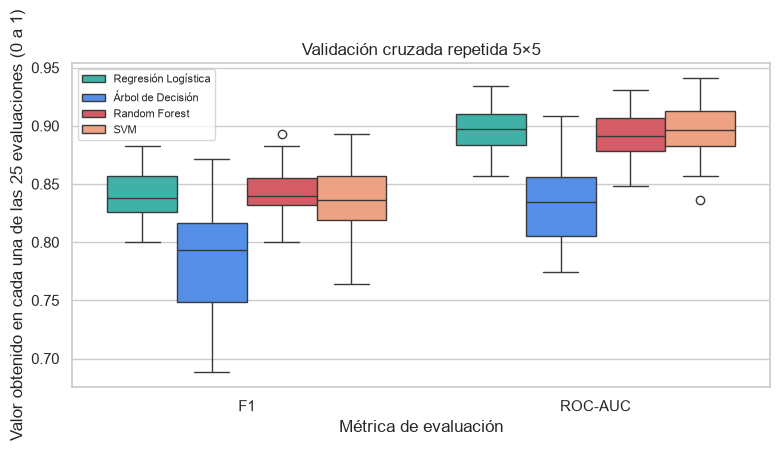

**Cómo leer la gráfica «Validación cruzada repetida 5×5»**

- **Eje X:** Métrica de evaluación (F1 y ROC-AUC).
- **Eje Y:** Valor de la métrica en cada una de las 25 evaluaciones. La caja contiene la mitad central de los resultados, la línea es la mediana y los bigotes el rango habitual.
- **Qué muestra:** Qué tan estable es cada modelo: cajas altas y cortas = bueno y consistente; cajas largas = depende mucho de la partición.
- **Resultado:** Las cajas de los modelos se superponen bastante; Random Forest tiene el mejor promedio de F1.
- **Para qué sirve:** Elegir un modelo confiable y no solo el que tuvo suerte en una partición.

In [17]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RS)
filas, largo = [], []
for n in ML:
    r = cross_validate(clone(modelos[n]), X_trva, y_trva, cv=rcv, n_jobs=N_JOBS, scoring=["accuracy", "f1", "recall", "roc_auc"])
    filas.append({"Modelo": n, **{f"{k} (media)": round(r["test_" + k].mean(), 3) for k in ["accuracy", "f1", "recall", "roc_auc"]},
                  "f1 (desv.)": round(r["test_f1"].std(), 3)})
    largo += [{"Modelo": n, "Métrica": k.upper() if k == "f1" else "ROC-AUC", "Valor": v} for k in ["f1", "roc_auc"] for v in r["test_" + k]]
t_rcv = pd.DataFrame(filas)
mas_estable = t_rcv.sort_values("f1 (media)", ascending=False).iloc[0].Modelo
tabla("T13_CV_repetida", t_rcv, "Validación cruzada repetida 5 × 5",
      f"Promedio de 25 evaluaciones por modelo sobre {len(y_trva)} pacientes (entrenamiento + validación).",
      "«media» es el promedio de las 25 evaluaciones; «desv.» cuánto varía de una partición a otra.",
      "Saber si las diferencias entre modelos son reales o fruto del azar de una sola partición.",
      f"Mayor F1 promedio: {mas_estable} ({t_rcv.set_index('Modelo').loc[mas_estable, 'f1 (media)']:.3f}).")
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.boxplot(data=pd.DataFrame(largo), x="Métrica", y="Valor", hue="Modelo", palette=COLORES, ax=ax)
ax.set_xlabel("Métrica de evaluación"); ax.set_ylabel("Valor obtenido en cada una de las 25 evaluaciones (0 a 1)")
ax.set_title("Validación cruzada repetida 5×5"); ax.legend(fontsize=8)
figura("G08_CV_repetida", fig, "Validación cruzada repetida 5×5",
       "Métrica de evaluación (F1 y ROC-AUC).",
       "Valor de la métrica en cada una de las 25 evaluaciones. La caja contiene la mitad central de los resultados, la línea es la mediana y los bigotes el rango habitual.",
       "Qué tan estable es cada modelo: cajas altas y cortas = bueno y consistente; cajas largas = depende mucho de la partición.",
       "Elegir un modelo confiable y no solo el que tuvo suerte en una partición.",
       f"Las cajas de los modelos se superponen bastante; {mas_estable} tiene el mejor promedio de F1.")

**Desempeño por hospital (prueba)**  
*Qué es:* Accuracy y Recall de cada modelo, calculados por separado para los pacientes de prueba de cada hospital.  
*Cómo leerla:* Cada fila es un hospital. Con pocos pacientes por hospital, estos valores varían mucho; sirven como orientación.  
*Para qué sirve:* Detectar si un modelo funciona bien en un hospital y mal en otro, señal de que no generaliza igual a todas las poblaciones.

,Hospital,Pacientes en prueba,% con enfermedad,Accuracy Regresión Logística,Recall Regresión Logística,Accuracy Árbol de Decisión,Recall Árbol de Decisión,Accuracy Random Forest,Recall Random Forest,Accuracy SVM,Recall SVM
0,Cleveland,46,45.7,0.804,0.810,0.739,0.667,0.804,0.714,0.848,0.810
1,Hungría,44,36.4,0.864,0.875,0.795,0.938,0.886,0.938,0.886,0.938
2,Suiza,18,94.4,0.889,0.882,0.833,0.824,0.944,0.941,0.889,0.941
3,VA Long Beach,30,73.3,0.733,0.727,0.700,0.818,0.767,0.864,0.833,0.909


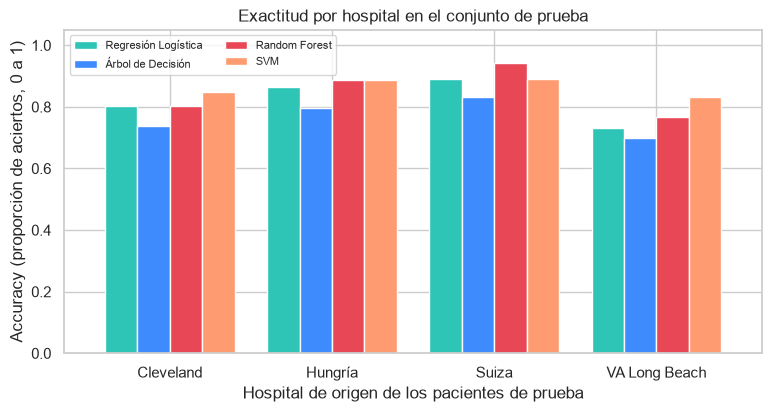

**Cómo leer la gráfica «Exactitud por hospital»**

- **Eje X:** Hospital de origen de los pacientes de prueba.
- **Eje Y:** Accuracy: proporción de pacientes bien clasificados en ese hospital (0 a 1).
- **Qué muestra:** Si los modelos aciertan por igual en todos los hospitales.
- **Resultado:** Para Random Forest, el hospital con menor exactitud es VA Long Beach.
- **Para qué sirve:** Saber en qué población es más confiable el modelo antes de pensar en usarlo en otro lugar.

In [18]:
filas = []
for h in ARCHIVOS:
    mk = (h_te == h).values
    fila = {"Hospital": h, "Pacientes en prueba": int(mk.sum()), "% con enfermedad": round(y_te[mk].mean() * 100, 1)}
    for n in ML:
        pr = (scores[n][mk] >= 0.5).astype(int)
        fila[f"Accuracy {n}"] = round(accuracy_score(y_te[mk], pr), 3)
        fila[f"Recall {n}"] = round(recall_score(y_te[mk], pr, zero_division=0), 3)
    filas.append(fila)
t_h = pd.DataFrame(filas)
tabla("T14_Por_hospital", t_h, "Desempeño por hospital (prueba)",
      "Accuracy y Recall de cada modelo, calculados por separado para los pacientes de prueba de cada hospital.",
      "Cada fila es un hospital. Con pocos pacientes por hospital, estos valores varían mucho; sirven como orientación.",
      "Detectar si un modelo funciona bien en un hospital y mal en otro, señal de que no generaliza igual a todas las poblaciones.")
fig, ax = plt.subplots(figsize=(9, 4.2))
t_h.set_index("Hospital")[[f"Accuracy {n}" for n in ML]].rename(columns=lambda c: c.replace("Accuracy ", "")).plot.bar(ax=ax, color=[COLORES[n] for n in ML], rot=0, width=.8)
ax.set_ylim(0, 1.05); ax.set_xlabel("Hospital de origen de los pacientes de prueba"); ax.set_ylabel("Accuracy (proporción de aciertos, 0 a 1)")
ax.set_title("Exactitud por hospital en el conjunto de prueba"); ax.legend(fontsize=8, ncol=2)
peor = t_h.set_index("Hospital")[f"Accuracy {mas_estable}"].idxmin()
figura("G09_Por_hospital", fig, "Exactitud por hospital",
       "Hospital de origen de los pacientes de prueba.",
       "Accuracy: proporción de pacientes bien clasificados en ese hospital (0 a 1).",
       "Si los modelos aciertan por igual en todos los hospitales.",
       "Saber en qué población es más confiable el modelo antes de pensar en usarlo en otro lugar.",
       f"Para {mas_estable}, el hospital con menor exactitud es {peor}.")

In [19]:
filas = []
for n in ML:
    for etiqueta, cats in (("13 variables", CAT), ("Sin ca ni thal (11)", [c for c in CAT if c not in ("ca", "thal")])):
        m = clone(modelos[n]); m.steps[0] = ("prep", preprocesador(cats))
        r = cross_validate(m, X_trva, y_trva, cv=cv5, n_jobs=N_JOBS, scoring=["f1", "roc_auc"])
        filas.append({"Modelo": n, "Variables": etiqueta, "F1": round(r["test_f1"].mean(), 3), "ROC-AUC": round(r["test_roc_auc"].mean(), 3)})
t_sens = pd.DataFrame(filas)
tabla("T15_Sensibilidad_ca_thal", t_sens, "Sensibilidad: ¿qué pasa sin ca y thal?",
      "Validación cruzada de cada modelo con las 13 variables y sin ca ni thal, que faltan en más de la mitad de los registros.",
      "Si el desempeño casi no cambia, el modelo no depende de esas dos variables; si cae mucho, sí.",
      "Saber si el modelo se apoya en variables que casi solo existen en Cleveland (y que podrían delatar el hospital).")

**Sensibilidad: ¿qué pasa sin ca y thal?**  
*Qué es:* Validación cruzada de cada modelo con las 13 variables y sin ca ni thal, que faltan en más de la mitad de los registros.  
*Cómo leerla:* Si el desempeño casi no cambia, el modelo no depende de esas dos variables; si cae mucho, sí.  
*Para qué sirve:* Saber si el modelo se apoya en variables que casi solo existen en Cleveland (y que podrían delatar el hospital).

,Modelo,Variables,F1,ROC-AUC
0,Regresión Logística,13 variables,0.841,0.901
1,Regresión Logística,Sin ca ni thal (11),0.827,0.889
2,Árbol de Decisión,13 variables,0.787,0.848
3,Árbol de Decisión,Sin ca ni thal (11),0.764,0.824
4,Random Forest,13 variables,0.845,0.894
5,Random Forest,Sin ca ni thal (11),0.834,0.887
6,SVM,13 variables,0.841,0.898
7,SVM,Sin ca ni thal (11),0.827,0.889


## 11. Comparación con un LLM local: Qwen 3.5 (9B) con GPU
Un **modelo de lenguaje grande (LLM)** es una red neuronal entrenada con enormes cantidades de texto; no fue entrenado con nuestros datos. Le damos a cada paciente de prueba **descrito en texto** y le pedimos que estime si tiene la enfermedad:
- **Zero-shot:** solo la descripción del paciente.
- **Few-shot:** además, 6 ejemplos resueltos tomados **del conjunto de entrenamiento** (3 con y 3 sin enfermedad).
- **Razonamiento (*thinking*):** zero-shot, pero dejando que el modelo «piense» paso a paso antes de responder.

Usamos **Qwen 3.5 de 9 mil millones de parámetros** (`qwen3.5:9b`, 6,6 GB cuantizado), el Qwen más capaz que cabe **completo** en una GPU de 8 GB. Los modelos más grandes (Qwen 3.5/3.6 de 27B o 35B) necesitan entre 17 y 24 GB.

**Costo del razonamiento:** sin razonamiento Qwen responde en ≈ 2 s por paciente; con razonamiento escribe miles de tokens de «pensamiento» antes de responder (≈ 200 s por paciente, **≈ 8 horas** para todo el conjunto de prueba). Por eso esa modalidad se controla con `RAZONAMIENTO = True/False` y su avance se guarda paciente por paciente en un archivo temporal (`resultado/_avance_llm.jsonl`), que se borra al terminar: si la ejecución se interrumpe, continúa donde iba.

Se pide respuesta en JSON con **riesgo 0-100** (permite calcular ROC-AUC) y **clase** 0/1, con `temperature = 0` y semilla fija.

In [20]:
OLLAMA_URL = "http://localhost:11434"
MODELO_LLM = "qwen3.5:9b"
USAR_GPU = True
RAZONAMIENTO = True            # ≈ 8 horas extra en una RTX 3050; False para omitirlo
MODOS = [("Qwen zero-shot", False, False), ("Qwen few-shot", True, False)] + ([("Qwen razonamiento", False, True)] if RAZONAMIENTO else [])
OPCIONES = {"temperature": 0, "seed": RS, "num_ctx": 4096, "num_predict": 40}
OPCIONES.update({"num_gpu": 99} if USAR_GPU else {"num_gpu": 0, "num_thread": N_JOBS})   # 99 = todas las capas en la GPU

def ollama_disponible():
    try:
        nombres = [m["name"] for m in requests.get(f"{OLLAMA_URL}/api/tags", timeout=5).json().get("models", [])]
        print("Ollama activo. Modelos instalados:", nombres)
        if MODELO_LLM not in nombres:
            print(f"Falta el modelo. Ejecute: ollama pull {MODELO_LLM}"); return False
        return True
    except requests.exceptions.RequestException:
        print("No se pudo conectar con Ollama en", OLLAMA_URL, "-> ejecute 'ollama serve'."); return False
OLLAMA_OK = ollama_disponible()

def describir(r):
    v = lambda x, fmt="{:.0f}", u="": "no registrado" if pd.isna(x) else fmt.format(x) + u
    t = lambda x: "no registrado" if x == "desconocido" else x
    return (f"Edad {v(r.age, u=' años')}; sexo {'masculino' if r.sex == 1 else 'femenino'}; tipo de dolor torácico: {t(r.cp)}; "
            f"presión arterial en reposo {v(r.trestbps, u=' mm Hg')}; colesterol sérico {v(r.chol, u=' mg/dl')}; "
            f"glucemia en ayunas > 120 mg/dl: {t(r.fbs)}; electrocardiograma en reposo: {t(r.restecg)}; "
            f"frecuencia cardíaca máxima {v(r.thalach, u=' lpm')}; angina inducida por ejercicio: {t(r.exang)}; "
            f"depresión del ST (oldpeak) {v(r.oldpeak, '{:.1f}')}; pendiente del ST: {t(r.slope)}; "
            f"vasos principales coloreados por fluoroscopia: {t(r.ca)}; prueba de talio: {t(r.thal)}.")

SISTEMA = ("Eres un asistente de apoyo para un ejercicio académico de clasificación con la base UCI Heart Disease "
           "(hospitales de Cleveland, Hungría, Suiza y VA Long Beach). Con base en las variables clínicas del paciente, "
           "estima si presenta enfermedad cardíaca (estrechamiento > 50 % en al menos un vaso coronario). "
           'Responde SOLO con JSON: {"riesgo": entero de 0 a 100, "clase": 1 si hay enfermedad o 0 si no}.')
ESQUEMA = {"type": "object", "properties": {"riesgo": {"type": "integer"}, "clase": {"type": "integer"}}, "required": ["riesgo", "clase"]}
ej = pd.concat([X_tr[y_tr == 1].sample(3, random_state=RS), X_tr[y_tr == 0].sample(3, random_state=RS)]).sample(frac=1, random_state=RS)
EJEMPLOS = []
for i, r in ej.iterrows():
    c = int(y.loc[i])
    EJEMPLOS += [{"role": "user", "content": describir(r)}, {"role": "assistant", "content": json.dumps({"riesgo": 80 if c else 20, "clase": c})}]
print("Ejemplo de descripción enviada al LLM:\n", describir(X_te.iloc[0]))

Ollama activo. Modelos instalados: ['qwen3.5:9b']
Ejemplo de descripción enviada al LLM:
 Edad 57 años; sexo masculino; tipo de dolor torácico: angina atípica; presión arterial en reposo 154 mm Hg; colesterol sérico 232 mg/dl; glucemia en ayunas > 120 mg/dl: no; electrocardiograma en reposo: hipertrofia VI; frecuencia cardíaca máxima 164 lpm; angina inducida por ejercicio: no; depresión del ST (oldpeak) 0.0; pendiente del ST: ascendente; vasos principales coloreados por fluoroscopia: 1; prueba de talio: normal.


In [21]:
def consultar_llm(texto, few_shot, pensar=False):
    msgs = [{"role": "system", "content": SISTEMA}] + (EJEMPLOS if few_shot else []) + [{"role": "user", "content": texto}]
    opciones = dict(OPCIONES, **({"num_ctx": 16384, "num_predict": 14000} if pensar else {}))
    cuerpo = {"model": MODELO_LLM, "messages": msgs, "stream": False, "options": opciones, "keep_alive": "30m", "think": pensar}
    if not pensar: cuerpo["format"] = ESQUEMA                   # con razonamiento se deja pensar libremente y se extrae el JSON final
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA_URL}/api/chat", json=cuerpo, timeout=3600).json()
    if "error" in r and "think" in r["error"]:                 # modelos sin modo de razonamiento
        cuerpo.pop("think"); r = requests.post(f"{OLLAMA_URL}/api/chat", json=cuerpo, timeout=3600).json()
    seg = time.perf_counter() - t0
    try:
        txt = r["message"]["content"]
        out = json.loads(txt[txt.rindex("{"):txt.rindex("}") + 1])
        riesgo = float(np.clip(out.get("riesgo", 50), 0, 100)); clase = int(int(out.get("clase", int(riesgo >= 50))) == 1)
    except Exception:
        riesgo, clase = np.nan, np.nan
    return riesgo, clase, seg, r.get("eval_count", np.nan)

AVANCE = f"{OUT}/_avance_llm.jsonl"
previas, gpu_info = [], None
if os.path.exists(EXCEL):                                      # reutiliza predicciones guardadas del mismo modelo
    try:
        prev = pd.read_excel(EXCEL, sheet_name="T16_Predicciones_LLM", header=6)
        previas += prev[prev.modelo == MODELO_LLM].to_dict("records")
        gpu_info = pd.read_excel(EXCEL, sheet_name="T17_Uso_GPU_LLM", header=6)
    except Exception:
        pass
if os.path.exists(AVANCE):
    previas += [json.loads(l) for l in open(AVANCE, encoding="utf-8") if l.strip()]
hechas = {(p["modo"], int(p["indice"])) for p in previas}
pendientes = sum((m, int(i)) not in hechas for m, _, _ in MODOS for i in X_te.index)
print(f"Predicciones ya guardadas: {len(hechas)} · pendientes: {pendientes}")
if pendientes and OLLAMA_OK:
    consultar_llm(describir(X_te.iloc[0]), False)               # calentamiento: carga el modelo en la GPU
    gpu_info = pd.DataFrame([{"Modelo": m["name"], "Tamaño total (GB)": round(m["size"] / 1e9, 2), "En GPU / VRAM (GB)": round(m.get("size_vram", 0) / 1e9, 2),
                              "% en GPU": round(m.get("size_vram", 0) / m["size"] * 100, 1), "Contexto (tokens)": m.get("context_length")}
                             for m in requests.get(f"{OLLAMA_URL}/api/ps").json().get("models", [])])
    with open(AVANCE, "a", encoding="utf-8") as fa:
        for modo, fs, pensar in MODOS:
            faltan = [i for i in X_te.index if (modo, int(i)) not in hechas]
            for k, i in enumerate(faltan, 1):
                riesgo, clase, seg, tokens = consultar_llm(describir(X_te.loc[i]), fs, pensar)
                fila = {"modelo": MODELO_LLM, "modo": modo, "indice": int(i), "hospital": hosp.loc[i], "real": int(y.loc[i]),
                        "riesgo": riesgo, "clase": clase, "segundos": round(seg, 3), "tokens_generados": tokens}
                previas.append(fila); fa.write(json.dumps(fila, default=float) + "\n"); fa.flush()
                if k % 10 == 0 or k == len(faltan) or pensar:
                    print(f"{modo}: {k}/{len(faltan)} ({seg:.1f} s)", flush=True)
orden = {m: k for k, (m, _, _) in enumerate(MODOS)}
pred_llm = pd.DataFrame(previas).drop_duplicates(["modo", "indice"], keep="last") if previas else None
if pred_llm is not None:
    pred_llm = pred_llm[pred_llm.modo.isin(orden)].assign(_o=lambda t: t.modo.map(orden)).sort_values(["_o", "indice"]).drop(columns="_o").reset_index(drop=True)
if gpu_info is not None:
    tabla("T17_Uso_GPU_LLM", gpu_info, "Uso de la GPU por el LLM",
          "Cuánta memoria ocupa Qwen y cuánta quedó en la VRAM de la GPU (consulta /api/ps de Ollama).",
          "Si «% en GPU» es 100, todo el modelo corre en la tarjeta gráfica.",
          "Verificar que la prueba realmente usó la GPU de 8 GB y que el modelo cabe completo.")

Predicciones ya guardadas: 307 · pendientes: 107


Qwen razonamiento: 1/107 (402.0 s)


Qwen razonamiento: 2/107 (151.0 s)


Qwen razonamiento: 3/107 (156.1 s)


Qwen razonamiento: 4/107 (196.1 s)


Qwen razonamiento: 5/107 (108.4 s)


... (100 outputs left out)

Qwen razonamiento: 106/107 (180.9 s)


Qwen razonamiento: 107/107 (183.6 s)


**Uso de la GPU por el LLM**  
*Qué es:* Cuánta memoria ocupa Qwen y cuánta quedó en la VRAM de la GPU (consulta /api/ps de Ollama).  
*Cómo leerla:* Si «% en GPU» es 100, todo el modelo corre en la tarjeta gráfica.  
*Para qué sirve:* Verificar que la prueba realmente usó la GPU de 8 GB y que el modelo cabe completo.

,Modelo,Tamaño total (GB),En GPU / VRAM (GB),% en GPU,Contexto (tokens)
0,qwen3.5:9b,5.33,5.33,100.0,4096


**Predicciones de Qwen paciente por paciente**  
*Qué es:* La respuesta de Qwen para cada paciente de prueba en las dos modalidades.  
*Cómo leerla:* real = diagnóstico verdadero; riesgo = estimación 0-100 de Qwen; clase = su predicción; segundos = tiempo de respuesta; tokens_generados = palabras/fragmentos que escribió (incluye el «pensamiento» en el modo razonamiento).  
*Para qué sirve:* Revisar casos concretos en los que el LLM acierta o falla y reutilizar las respuestas sin volver a consultar el modelo.

,modelo,modo,indice,hospital,real,riesgo,clase,segundos,tokens_generados
0,qwen3.5:9b,Qwen zero-shot,1,Cleveland,1,92.0,1.0,1.506,16
1,qwen3.5:9b,Qwen zero-shot,3,Cleveland,0,92.0,1.0,1.495,16
2,qwen3.5:9b,Qwen zero-shot,21,Cleveland,0,95.0,1.0,1.490,16
3,qwen3.5:9b,Qwen zero-shot,23,Cleveland,1,95.0,1.0,1.477,16
4,qwen3.5:9b,Qwen zero-shot,31,Cleveland,1,95.0,1.0,1.465,16
...,...,...,...,...,...,...,...,...,...
409,qwen3.5:9b,Qwen razonamiento,886,VA Long Beach,0,76.0,1.0,191.761,6166
410,qwen3.5:9b,Qwen razonamiento,902,VA Long Beach,1,82.0,1.0,186.299,5977
411,qwen3.5:9b,Qwen razonamiento,904,VA Long Beach,1,62.0,1.0,173.284,5566
412,qwen3.5:9b,Qwen razonamiento,907,VA Long Beach,0,32.0,0.0,286.306,9135


Qwen zero-shot: inválidas 0/138 · 1.49 s/paciente · total 0.06 h · predichos enfermos 75 %
Qwen few-shot: inválidas 0/138 · 1.65 s/paciente · total 0.06 h · predichos enfermos 64 %
Qwen razonamiento: inválidas 3/138 · 185.59 s/paciente · total 7.11 h · predichos enfermos 68 %


**Tiempo de Qwen por modalidad**  
*Qué es:* Cuánto tardó Qwen por paciente y en total en cada modalidad, y cuántos tokens escribió en promedio.  
*Cómo leerla:* Seg_por_paciente = segundos promedio por respuesta; Horas_totales = tiempo para todo el conjunto de prueba.  
*Para qué sirve:* Valorar el costo de cómputo de cada modalidad frente a la mejora que aporta.

,modo,Pacientes,Seg_por_paciente,Horas_totales,Tokens_promedio
0,Qwen zero-shot,138,1.494,0.057,15.906
1,Qwen few-shot,138,1.652,0.063,15.993
2,Qwen razonamiento,138,185.592,7.114,5941.471


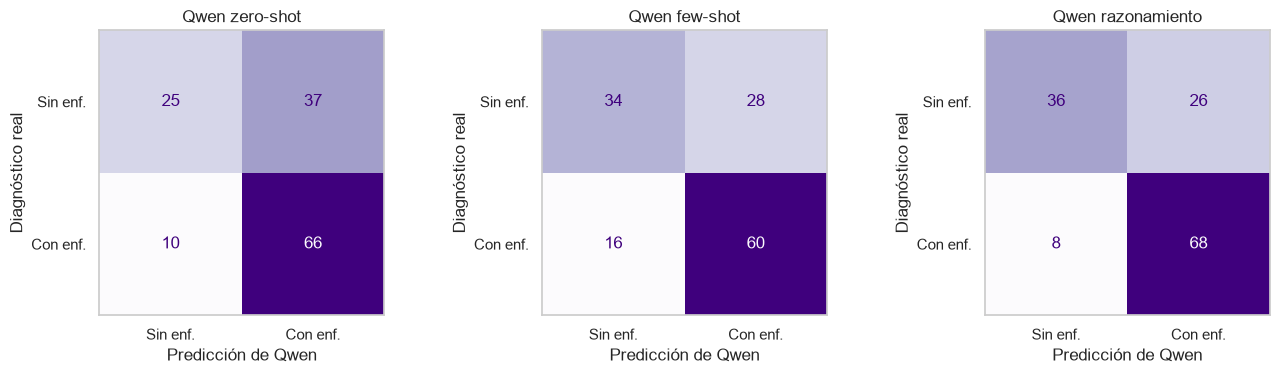

**Cómo leer la gráfica «Matrices de confusión de Qwen»**

- **Eje X:** Lo que predijo Qwen: «Sin enf.» o «Con enf.».
- **Eje Y:** El diagnóstico real. Diagonal = aciertos; abajo a la izquierda = enfermos no detectados; arriba a la derecha = sanos alertados.
- **Qué muestra:** Cómo se equivoca el LLM en cada modalidad.
- **Resultado:** Porcentaje de pacientes que Qwen marcó como enfermos: zero-shot 75 %, few-shot 64 %, razonamiento 70 % (enfermos reales: 55 %).
- **Para qué sirve:** Ver si el LLM tiene un sesgo (por ejemplo, decir «enfermo» casi siempre).

In [22]:
f_llm, t_llm = {}, {}
if pred_llm is not None:
    tabla("T16_Predicciones_LLM", pred_llm, "Predicciones de Qwen paciente por paciente",
          "La respuesta de Qwen para cada paciente de prueba en las dos modalidades.",
          "real = diagnóstico verdadero; riesgo = estimación 0-100 de Qwen; clase = su predicción; segundos = tiempo de respuesta; tokens_generados = palabras/fragmentos que escribió (incluye el «pensamiento» en el modo razonamiento).",
          "Revisar casos concretos en los que el LLM acierta o falla y reutilizar las respuestas sin volver a consultar el modelo.")
    for modo, g in pred_llm.groupby("modo", sort=False):
        inval = int(g.clase.isna().sum()); g = g.fillna({"riesgo": 50, "clase": 0})
        f_llm[modo] = metricas(g.real, g.clase.astype(int), g.riesgo); t_llm[modo] = g.segundos.mean()
        print(f"{modo}: inválidas {inval}/{len(g)} · {g.segundos.mean():.2f} s/paciente · total {g.segundos.sum()/3600:.2f} h · predichos enfermos {g.clase.mean()*100:.0f} %")
    tiempos_llm = pred_llm.groupby("modo", sort=False).agg(Pacientes=("indice", "size"), Seg_por_paciente=("segundos", "mean"),
                  Horas_totales=("segundos", lambda v: v.sum() / 3600), Tokens_promedio=("tokens_generados", "mean")).round(3).reset_index()
    tabla("T20_Tiempos_LLM", tiempos_llm, "Tiempo de Qwen por modalidad",
          "Cuánto tardó Qwen por paciente y en total en cada modalidad, y cuántos tokens escribió en promedio.",
          "Seg_por_paciente = segundos promedio por respuesta; Horas_totales = tiempo para todo el conjunto de prueba.",
          "Valorar el costo de cómputo de cada modalidad frente a la mejora que aporta.")
    nm = pred_llm.modo.nunique()
    fig, ax = plt.subplots(1, nm, figsize=(4.5 * nm, 3.9))
    for a, (modo, g) in zip(ax, pred_llm.groupby("modo", sort=False)):
        ConfusionMatrixDisplay(confusion_matrix(g.real, g.clase.fillna(0).astype(int)), display_labels=["Sin enf.", "Con enf."]).plot(ax=a, cmap="Purples", colorbar=False)
        a.set_title(modo); a.set_xlabel("Predicción de Qwen"); a.set_ylabel("Diagnóstico real"); a.grid(False)
    plt.tight_layout()
    pct_enf = ", ".join(f"{m.replace('Qwen ', '')} {g.clase.mean()*100:.0f} %" for m, g in pred_llm.groupby("modo", sort=False))
    figura("G10_Matrices_LLM", fig, "Matrices de confusión de Qwen",
           "Lo que predijo Qwen: «Sin enf.» o «Con enf.».",
           "El diagnóstico real. Diagonal = aciertos; abajo a la izquierda = enfermos no detectados; arriba a la derecha = sanos alertados.",
           "Cómo se equivoca el LLM en cada modalidad.",
           "Ver si el LLM tiene un sesgo (por ejemplo, decir «enfermo» casi siempre).",
           f"Porcentaje de pacientes que Qwen marcó como enfermos: {pct_enf} (enfermos reales: {y_te.mean()*100:.0f} %).")

## 12. Comparación global: Machine Learning vs. Qwen

**Comparación final en el conjunto de prueba**  
*Qué es:* Todos los modelos (Machine Learning y Qwen) evaluados con los mismos pacientes de prueba.  
*Cómo leerla:* Métricas de 0 a 1 (más alto es mejor) y segundos que tarda cada modelo en responder por paciente.  
*Resultado:* Mejor ML: SVM (F1 0.877); mejor Qwen: Qwen razonamiento (F1 0.800), ≈ 185.6 s por paciente frente a 0.06 ms.  
*Para qué sirve:* Decidir qué tipo de modelo conviene para este problema, considerando precisión y costo de cómputo.

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,Tiempo por paciente (s),Aprende de los datos
0,Línea base,0.551,0.551,1.000,0.710,0.500,NaN,—
1,Regresión Logística,0.819,0.849,0.816,0.832,0.913,0.00005,Sí
2,Árbol de Decisión,0.761,0.772,0.803,0.787,0.855,0.00005,Sí
3,Random Forest,0.841,0.855,0.855,0.855,0.910,0.00026,Sí
4,SVM,0.862,0.861,0.895,0.877,0.916,0.00006,Sí
5,Qwen zero-shot,0.659,0.641,0.868,0.737,0.722,1.49441,No
6,Qwen few-shot,0.681,0.682,0.789,0.732,0.744,1.65160,No
7,Qwen razonamiento,0.754,0.723,0.895,0.800,0.836,185.59212,No


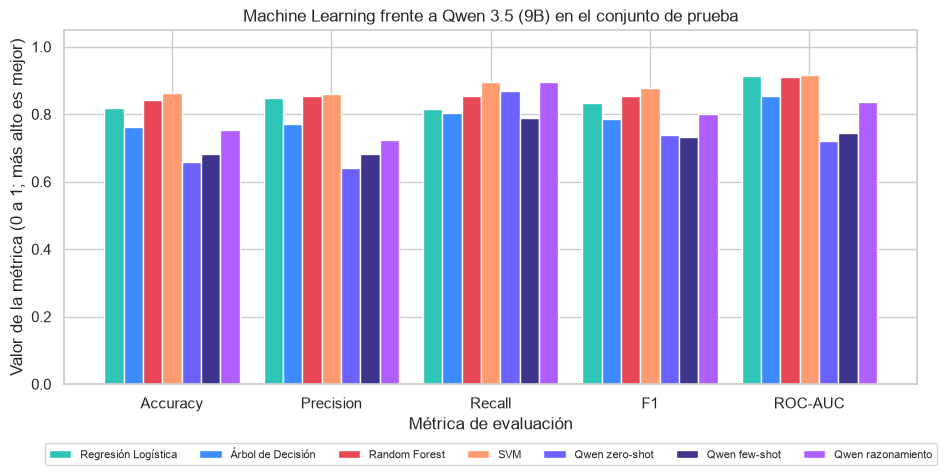

**Cómo leer la gráfica «Machine Learning frente a Qwen»**

- **Eje X:** Las cinco métricas de evaluación.
- **Eje Y:** Valor de cada métrica (0 a 1; más alto es mejor). Las barras moradas son Qwen.
- **Qué muestra:** Si un LLM general, sin entrenar con estos datos, alcanza a los modelos entrenados.
- **Resultado:** Qwen razonamiento logra F1 0.800 frente a 0.877 de SVM.
- **Para qué sirve:** Justificar la elección de un modelo entrenado y conocer el aporte real de un LLM local.

In [23]:
comp = pd.concat([t_te, pd.DataFrame(f_llm).T.round(3)])
comp["Tiempo por paciente (s)"] = pd.Series({**tiempos, **t_llm}).round(5)
comp["Aprende de los datos"] = ["—"] + ["Sí"] * len(ML) + ["No"] * len(f_llm)
mejor_llm = max(f_llm, key=lambda k: f_llm[k]["F1"]) if f_llm else None
tabla("T18_Comparacion_final", comp.reset_index().rename(columns={"index": "Modelo"}), "Comparación final en el conjunto de prueba",
      "Todos los modelos (Machine Learning y Qwen) evaluados con los mismos pacientes de prueba.",
      "Métricas de 0 a 1 (más alto es mejor) y segundos que tarda cada modelo en responder por paciente.",
      "Decidir qué tipo de modelo conviene para este problema, considerando precisión y costo de cómputo.",
      (f"Mejor ML: {mej} (F1 {t_te.loc[mej, 'F1']:.3f}); mejor Qwen: {mejor_llm} (F1 {f_llm[mejor_llm]['F1']:.3f}), "
       f"≈ {t_llm[mejor_llm]:.1f} s por paciente frente a {tiempos[mej]*1000:.2f} ms.") if mejor_llm else "")
todos = ML + list(f_llm)
fig, ax = plt.subplots(figsize=(11, 4.6))
comp.loc[todos, mets].T.plot.bar(ax=ax, width=.85, color=[COLORES[m] for m in todos], rot=0)
ax.set_ylim(0, 1.05); ax.set_xlabel("Métrica de evaluación"); ax.set_ylabel("Valor de la métrica (0 a 1; más alto es mejor)")
ax.set_title("Machine Learning frente a Qwen 3.5 (9B) en el conjunto de prueba"); ax.legend(ncol=7, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.15))
figura("G11_Comparacion_final", fig, "Machine Learning frente a Qwen",
       "Las cinco métricas de evaluación.",
       "Valor de cada métrica (0 a 1; más alto es mejor). Las barras moradas son Qwen.",
       "Si un LLM general, sin entrenar con estos datos, alcanza a los modelos entrenados.",
       "Justificar la elección de un modelo entrenado y conocer el aporte real de un LLM local.",
       (f"Qwen {mejor_llm.replace('Qwen ', '')} logra F1 {f_llm[mejor_llm]['F1']:.3f} frente a {t_te.loc[mej, 'F1']:.3f} de {mej}.") if mejor_llm else "")

In [24]:
lit = pd.DataFrame([
    ["Dwivedi (2018)", "UCI (Cleveland)", "Regresión Logística", 0.85],
    ["Al-Alshaikh et al. (2024)", "UCI Cleveland", "CNN + optimización", 0.891],
    ["Alsabhan y Alfadhly (2025)", "UCI 4 hospitales (como nosotros)", "Gradient Boosting", 0.902],
    ["Gárate-Escamila et al. (2020)", "Cleveland + Hungría", "Chi² + PCA + Random Forest", 0.994],
    ["MediRisk ML (prueba)", "UCI 4 hospitales", mej, round(t_te.loc[mej, "Accuracy"], 3)],
    ["MediRisk ML (CV 5×5)", "UCI 4 hospitales", mas_estable, t_rcv.set_index("Modelo").loc[mas_estable, "accuracy (media)"]],
] + ([["MediRisk ML (LLM)", "UCI 4 hospitales", f"{MODELO_LLM} {mejor_llm.replace('Qwen ', '')}", round(f_llm[mejor_llm]["Accuracy"], 3)]] if mejor_llm else []),
    columns=["Estudio", "Datos", "Modelo", "Accuracy"])
tabla("T19_Literatura", lit, "Comparación con la literatura",
      "Exactitud reportada por los estudios del estado del arte y la obtenida por nosotros.",
      "Cada fila es un estudio. Ojo: cada uno usa particiones y preprocesamientos distintos, así que la comparación es orientativa.",
      "Ubicar nuestros resultados frente a trabajos publicados; el más comparable es Alsabhan y Alfadhly (2025), que también usa los 4 hospitales.")

**Comparación con la literatura**  
*Qué es:* Exactitud reportada por los estudios del estado del arte y la obtenida por nosotros.  
*Cómo leerla:* Cada fila es un estudio. Ojo: cada uno usa particiones y preprocesamientos distintos, así que la comparación es orientativa.  
*Para qué sirve:* Ubicar nuestros resultados frente a trabajos publicados; el más comparable es Alsabhan y Alfadhly (2025), que también usa los 4 hospitales.

,Estudio,Datos,Modelo,Accuracy
0,Dwivedi (2018),UCI (Cleveland),Regresión Logística,0.850
1,Al-Alshaikh et al. (2024),UCI Cleveland,CNN + optimización,0.891
2,Alsabhan y Alfadhly (2025),UCI 4 hospitales (como nosotros),Gradient Boosting,0.902
3,Gárate-Escamila et al. (2020),Cleveland + Hungría,Chi² + PCA + Random Forest,0.994
4,MediRisk ML (prueba),UCI 4 hospitales,SVM,0.862
5,MediRisk ML (CV 5×5),UCI 4 hospitales,Random Forest,0.826
6,MediRisk ML (LLM),UCI 4 hospitales,qwen3.5:9b razonamiento,0.754


## 13. Exportación: un único Excel con todas las tablas y gráficas

In [25]:
from openpyxl import Workbook
from openpyxl.drawing.image import Image as XLImage
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

AZUL, CORAL = "1D1A39", "E84855"
wb = Workbook(); ix = wb.active; ix.title = "Indice"
ix["A1"] = "MediRisk ML · Entregable 3 · Resultados"; ix["A1"].font = Font(bold=True, size=16, color=AZUL)
ix["A2"] = "Cada hoja contiene una tabla o una gráfica con su explicación: qué es, cómo leerla (ejes X e Y), resultado y para qué sirve."
ix["A2"].alignment = Alignment(wrap_text=True)
ix.append([]); ix.append(["Hoja", "Tipo", "Título", "Para qué sirve"])
for c in ix[4]: c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor=AZUL)

def meta(ws, filas):
    for k, (etq, txt) in enumerate(filas, 1):
        ws.cell(k, 1, etq).font = Font(bold=True, color=CORAL if k == 1 else AZUL, size=14 if k == 1 else 11)
        c = ws.cell(k, 2, txt); c.alignment = Alignment(wrap_text=True, vertical="top")
        ws.merge_cells(start_row=k, start_column=2, end_row=k, end_column=10)
        ws.row_dimensions[k].height = 18 if k == 1 else max(30, 15 * (len(str(txt)) // 120 + 1))
    ws.column_dimensions["A"].width = 18

for clave, t in TABLAS.items():
    ws = wb.create_sheet(clave[:31])
    meta(ws, [(t["titulo"], ""), ("Qué es", t["que"]), ("Cómo leerla", t["leer"]), ("Resultado", t["resultado"] or "—"), ("Para qué sirve", t["uso"])])
    df = t["df"].reset_index(drop=True)
    for j, col in enumerate(df.columns, 1):
        c = ws.cell(7, j, str(col)); c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor=AZUL)
        c.alignment = Alignment(wrap_text=True, vertical="center")
        ws.column_dimensions[get_column_letter(j)].width = max(ws.column_dimensions[get_column_letter(j)].width or 0,
                                                              min(60, max(12, df[col].astype(str).str.len().max() * 0.9 if len(df) else 12, len(str(col)) * 1.1)))
        for i, v in enumerate(df[col], 8):
            v = None if (isinstance(v, float) and np.isnan(v)) else (v.item() if hasattr(v, "item") else v)
            ws.cell(i, j, v).alignment = Alignment(wrap_text=True, vertical="top")
    ws.freeze_panes = "A8"
    ix.append([clave, "Tabla", t["titulo"], t["uso"]])

for clave, f in FIGURAS.items():
    ws = wb.create_sheet(clave[:31])
    meta(ws, [(f["titulo"], ""), ("Eje X", f["eje_x"]), ("Eje Y", f["eje_y"]), ("Qué muestra", f["que"]),
              ("Resultado", f["resultado"] or "—"), ("Para qué sirve", f["uso"])])
    img = XLImage(io.BytesIO(f["png"])); escala = min(1.0, 1100 / img.width)
    img.width, img.height = int(img.width * escala), int(img.height * escala)
    ws.add_image(img, "A8")
    ix.append([clave, "Gráfica", f["titulo"], f["uso"]])

for r in range(5, ix.max_row + 1):
    ix.cell(r, 1).hyperlink = f"#'{ix.cell(r, 1).value}'!A1"; ix.cell(r, 1).font = Font(color="3D348B", underline="single")
    for c in range(1, 5): ix.cell(r, c).alignment = Alignment(wrap_text=True, vertical="top")
for col, wdt in zip("ABCD", (30, 10, 45, 90)): ix.column_dimensions[col].width = wdt
wb.save(EXCEL)
if pred_llm is not None and os.path.exists(AVANCE) and len(pred_llm) == len(MODOS) * len(X_te):
    os.remove(AVANCE); print("Avance temporal del LLM eliminado: todo quedó dentro del Excel.")
print(f"Excel guardado en {EXCEL}: {len(TABLAS)} tablas y {len(FIGURAS)} gráficas.")

Avance temporal del LLM eliminado: todo quedó dentro del Excel.
Excel guardado en resultado/MediRisk_ML_Entregable3_resultados.xlsx: 21 tablas y 11 gráficas.


## 14. Conclusiones

_Cifras de la ejecución de referencia (conjunto de prueba: 138 pacientes de los 4 hospitales; equipo: GNU/Linux Arch, KDE Plasma, Wayland, GPU NVIDIA RTX 3050 de 8 GB de VRAM)._

1. **Más datos, resultados más realistas.** Al unir Cleveland, Hungría, Suiza y VA Long Beach pasamos de 303 a 918 pacientes únicos. Los datos son más variados y tienen más faltantes, pero los resultados se parecen más a lo que pasaría en hospitales reales.
2. **Los modelos entrenados funcionan bien.** En prueba, SVM obtuvo el mayor F1 (0,877; ROC-AUC 0,916), seguido de Random Forest (0,855), Regresión Logística (0,832) y el Árbol de Decisión (0,787). Todos superan con claridad a la línea base (F1 0,710, que siempre dice «enfermo»).
3. **Recomendamos Random Forest.** Fue el mejor en validación (F1 0,844) y en la validación cruzada repetida 5×5 (F1 0,842 ± 0,022). La prueba solo se usa para estimar el resultado final, no para elegir el modelo; por eso SVM, aunque ganó en prueba, no cambia la elección.
4. **Pesos de clase: decisión honesta.** En estos datos la mayoría (55 %) son enfermos, así que el peso «balanced» favorece un poco a los sanos: el Recall promedio bajó de 0,852 a 0,824. En un uso clínico real convendría dar más peso a los enfermos a propósito o bajar el umbral de decisión.
5. **El árbol de decisión explica el problema.** Su primera pregunta es si el dolor de pecho es «asintomático», y las variables más importantes coinciden con la medicina (tipo de dolor, depresión del ST, frecuencia cardíaca máxima, angina por ejercicio).
6. **Robustez.** Quitar `ca` y `thal` (las variables con más faltantes) baja el F1 como máximo 0,023. VA Long Beach es el hospital más difícil.
7. **Qwen 3.5 (9B) en GPU local no reemplaza a un modelo entrenado.** El modelo se cargó 100 % en la VRAM (5,3 GB). Sin razonamiento tardó unos 1,5 s por paciente (F1 0,737 zero-shot; 0,732 few-shot). Con razonamiento tardó unas 7,1 horas en el conjunto de prueba (≈ 186 s y ≈ 5.900 tokens por paciente) y el F1 subió a 0,800: supera al Árbol de Decisión (0,787), pero queda por debajo de SVM (0,877), Random Forest (0,855) y Regresión Logística (0,832), y en exactitud y ROC-AUC queda por debajo de los cuatro, que además responden en fracciones de milisegundo.
8. **Nota sobre el modo razonamiento.** En 3 de 138 pacientes Qwen agotó el límite de 14.000 tokens pensando y no respondió; se contaron como «sin enfermedad» (en los tres casos ese era el diagnóstico real). Si se contaran como errores, su F1 sería ≈ 0,786.
9. **Todo queda en un solo archivo:** `resultado/MediRisk_ML_Entregable3_resultados.xlsx` reúne las 21 tablas y las 11 gráficas, cada una con su explicación (qué es, cómo leerla, ejes X e Y, resultado y para qué sirve).
